# CARE wind-turbine SCADA: CatBoost baseline for daily maintenance risk

**Goal.** For every turbine and every day, the probability that the turbine needs maintenance, and a flag above a threshold
that was chosen on training data only. This notebook is the **baseline** the LSTM-with-attention model will be compared
against, on the same folds (saved in `dataset/wind_turbine_scada_fault/cache/catboost_baseline/cv_folds.parquet`).

**What "needs maintenance" means here.** The feature explorer (`notebooks/care_feature_explorer.ipynb`, section 6) found no
column that separates anomaly from normal datasets in the 7 days before onset beyond what noise gives, while the signal is
clearly present *inside* the labelled event window. So the target is **"day t is inside an anomaly window, or one starts
within the next k days"** (k = 1 to 7), not "a precursor is visible". The strict variant "an anomaly window starts within
the next k days" (days already inside a window excluded) is reported as a secondary target, to show how much of the
performance comes from detecting a fault that is already there.

Rules carried over from the earlier notebooks: comma CSV variant only; `status_type_id` is never an input or a filter;
no cumulative counters, row counts or masks as features; no column list hand-picked from the explorer's ranking (it was
chosen on all datasets, so it would leak); time axis is `time_stamp`, not `id`; exact zeros in temperature columns are
dropped readings.

Sections: 1 columns and rules, 2 timelines (which datasets really overlap), 3 daily deviation table with a strictly
trailing baseline, 4 labels, 5 features, 6 folds, 7 training and evaluation engine, 8 results, 9 horizons and the strict
target, 10 ablations, 11 feature importance and season-aware correlation, 12 calibration, 13 the test-week table,
14 what does not work.

In [1]:
import io
import re
import time
import warnings
import zlib
from concurrent.futures import ThreadPoolExecutor
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.csv as pacsv
from catboost import CatBoostClassifier, Pool
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image as PILImage
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import average_precision_score, brier_score_loss, roc_auc_score
from sklearn.model_selection import StratifiedGroupKFold

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 60)
pd.set_option("display.notebook_repr_html", False)   # plain-text tables keep the notebook under the repo's 500 KB limit

ROOT = Path.cwd().resolve()
while not (ROOT / "CLAUDE.md").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW = ROOT / "dataset" / "wind_turbine_scada_fault" / "raw"
CACHE = ROOT / "dataset" / "wind_turbine_scada_fault" / "cache"
OUT = CACHE / "catboost_baseline"
OUT.mkdir(parents=True, exist_ok=True)

REBUILD_FEATURES = False   # the daily deviation table (section 3); a few minutes
REBUILD_CV = False         # every cross-validated model run (sections 8 to 11)

FARMS = ["A", "B", "C"]
BASE_COLS = ["time_stamp", "asset_id", "id", "train_test", "status_type_id"]
# operating-point covariates: wind speed, active power, ambient temperature (10-minute averages)
COV = {"A": dict(ws="wind_speed_3_avg", p="power_30_avg", amb="sensor_0_avg"),
       "B": dict(ws="wind_speed_61_avg", p="power_62_avg", amb="sensor_8_avg"),
       "C": dict(ws="wind_speed_236_avg", p="power_6_avg", amb="sensor_7_avg")}
# Farm B has no relative wind direction; the yaw error is rebuilt from absolute wind direction minus nacelle direction
YAW_FROM = {"B": ("sensor_4_avg", "sensor_21_avg")}

MIN_ROWS_PER_DAY = 48      # of 144 ten-minute rows; fewer valid rows and the day is not used
BASE_FROM, BASE_TO = 180, 60   # trailing baseline of FIXED length: days [t-180, t-60) (why fixed: section 3)
REFIT_DAYS = 30            # the baseline is refitted every 30 days, so the gap to day t is 60 to 89 days
MIN_BASELINE_DAYS = 90     # valid days needed in the 120-day baseline window; otherwise "baseline period", unused
BASELINE_ROWS = 20_000     # rows sampled from the baseline window for the fits
CLIP = 10.0                # |robust z| is clipped here
HORIZONS = list(range(1, 8))
GRAY_DAYS = 7
REPAIR_DAYS = 14
SEEDS = [0, 1, 2]
FA_BUDGET = 1.0            # false alarms per turbine-month (30 negative days)
REARM_DAYS = 7             # a continuing alarm notifies again every 7 days, so a permanent alarm is not one false alarm
N_BOOT = 1000
CB_PARAMS = dict(depth=4, iterations=400, learning_rate=0.05, l2_leaf_reg=20, rsm=0.3, border_count=64,
                 loss_function="Logloss", thread_count=-1, verbose=False, allow_writing_files=False)
DAY = np.timedelta64(1, "D")

SURFACE, INK, INK2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#c9c8c2"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#c0392b"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10, "figure.dpi": 110,
})


def show(fig, dpi=80, colors=96):
    """Show a figure as a small palette PNG, so the notebook stays under the repo's 500 KB file limit.

    The full-resolution PNG of every figure is saved separately in the cache folder.
    """
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=dpi, bbox_inches="tight")
    plt.close(fig)
    img = PILImage.open(buf).convert("RGB").quantize(colors=colors)
    out = io.BytesIO()
    img.save(out, format="PNG", optimize=True)
    display(IPImage(out.getvalue()))


T0 = time.time()
print("root:", ROOT)

root: /Users/alexandrucojoaca/Documents/Smarthack


## 1. Columns: which ones go in, by rule

Every rule below is decided from column metadata or from the unlabelled distribution of the column, never from the labels:

- only `_avg` and `_std` statistics (`_min` and `_max` are redundant with them);
- counters out: flagged `is_counter`, energy units (Wh, VArh, kWh, kvarh) and Farm A's unsuffixed `sensor_44` to
  `sensor_51`;
- absolute wind direction and nacelle direction out (circular, and they only say where the wind comes from); relative
  wind direction is wrapped to +-180 and kept as a yaw error; Farm B has no relative direction, so its yaw error is
  rebuilt as absolute wind direction minus nacelle direction, wrapped; pitch and blade or motor positions are not circular
  and stay numeric;
- quasi-constant columns out (5th percentile equals the 95th) and columns with more than 50% missing out, both measured
  on a sample of all rows of the farm after cleaning;
- wind speed and ambient temperature are **covariates only**: they define the operating point, they are not deviation
  features. Active power becomes a power-curve residual (power against wind and ambient).

Sensor groups (for the group aggregates and the pooled model) come from keywords in the sensor description.

In [2]:
def category(desc, unit):
    d, u = str(desc).lower(), str(unit).lower()
    if "temp" in d:
        return "temperature"
    if "vibration" in d:
        return "vibration"
    if "pressure" in d or u in ("bar", "pa"):
        return "pressure"
    if "wind" in d or "yaw error" in d:
        return "wind"
    if "pitch" in d or "position" in d or "angle" in d:
        return "pitch"
    if "rpm" in u or "1/min" in u or "speed" in d or "rotor" in d:
        return "speed"
    if "power" in d or u in ("kw", "kvar", "kva", "kwh", "kvarh"):
        return "power"
    if u == "a" or "current" in d:
        return "electrical"
    if u == "v" or "voltage" in d:
        return "electrical"
    return "other"


def dataset_paths(farm):
    return sorted((RAW / f"Wind Farm {farm}" / "datasets").glob("comma_*.csv"), key=lambda p: int(p.stem.split("_")[1]))


def wrap180(x):
    return (x + 180.0) % 360.0 - 180.0


def column_table(farm):
    names = pacsv.open_csv(dataset_paths(farm)[0]).schema.names
    desc = pd.read_csv(RAW / f"Wind Farm {farm}" / "comma_feature_description.csv", encoding="latin-1")
    rows = []
    for n in names:
        if n in BASE_COLS:
            continue
        m = re.match(r"^(.*)_(avg|min|max|std)$", n)
        rows.append((n, m.group(1), m.group(2)) if m else (n, n, "val"))
    fm = pd.DataFrame(rows, columns=["column", "sensor_name", "stat"]).merge(
        desc.drop(columns="statistics_type"), on="sensor_name", how="left")
    if farm in YAW_FROM:
        fm.loc[len(fm)] = {"column": "yaw_error_avg", "sensor_name": "yaw_error", "stat": "avg", "unit": "deg",
                           "description": "Yaw error (absolute wind direction minus nacelle direction, wrapped)",
                           "is_angle": False, "is_counter": False}
    d, u = fm["description"].astype(str).str.lower(), fm["unit"].astype(str).str.lower()
    fm["group"] = [category(a, b) for a, b in zip(fm["description"], fm["unit"])]
    fm["is_temp"] = d.str.contains("temp")
    fm["rel_dir"] = d.str.contains("relative") & d.str.contains("direction")
    counter = fm["is_counter"].fillna(False).astype(bool) | u.isin(["wh", "varh", "kwh", "kvarh"]) | (fm["stat"] == "val")
    abs_dir = fm["is_angle"].fillna(False).astype(bool) & d.str.contains("direction") & ~fm["rel_dir"]
    reason = np.select(
        [counter, abs_dir, fm["stat"].isin(["min", "max"]),
         fm["column"].isin([COV[farm]["ws"], COV[farm]["amb"]])],
        ["counter", "absolute direction (circular)", "min/max (redundant)", "covariate only"], default="")
    fm["reason"] = reason
    fm.loc[fm["column"] == COV[farm]["p"], "role"] = "power-curve residual"
    fm["role"] = fm["role"].fillna("")
    return fm


def read_columns(path, cols):
    have = set(pacsv.open_csv(path).schema.names)
    t = pacsv.read_csv(path, convert_options=pacsv.ConvertOptions(include_columns=["time_stamp"] + [c for c in cols if c in have]))
    ts = t["time_stamp"].to_numpy().astype("datetime64[s]")
    X = np.full((t.num_rows, len(cols)), np.nan, np.float32)
    for j, c in enumerate(cols):
        if c in have:
            X[:, j] = t[c].to_numpy(zero_copy_only=False)
    return ts, X


def clean(X, cols, farm, fm):
    """Dropped temperature readings to NaN, wrap relative directions, rebuild Farm B's yaw error, negative wind to NaN."""
    info = fm.set_index("column")
    for j, c in enumerate(cols):
        if c not in info.index:
            continue
        r = info.loc[c]
        if r["is_temp"] and r["stat"] != "std":
            X[X[:, j] == 0.0, j] = np.nan
        if r["rel_dir"] and r["stat"] == "avg":
            X[:, j] = wrap180(X[:, j])
    if farm in YAW_FROM and "yaw_error_avg" in cols:
        a, b = (cols.index(c) for c in YAW_FROM[farm])
        X[:, cols.index("yaw_error_avg")] = wrap180(X[:, a] - X[:, b])
    ws = cols.index(COV[farm]["ws"])
    X[X[:, ws] < 0, ws] = np.nan
    return X


def sample_stats(farm, fm, cands):
    """5th/95th percentile and missing share of every candidate column, on every 10th row of every dataset."""
    cols = cands + ([c for c in YAW_FROM.get(farm, ()) if c not in cands])

    def one(path):
        ts, X = read_columns(path, cols)
        return clean(X, cols, farm, fm)[::10]

    with ThreadPoolExecutor(max_workers=6) as ex:
        S = np.vstack(list(ex.map(one, dataset_paths(farm))))
    S = S[:, : len(cands)]
    return pd.DataFrame({"nan_frac": np.isnan(S).mean(0), "p05": np.nanpercentile(S, 5, axis=0),
                         "p95": np.nanpercentile(S, 95, axis=0)}, index=cands)


FM, DEV_COLS = {}, {}
inv_rows = []
for f in FARMS:
    fm = column_table(f)
    cand = fm.loc[fm["reason"].isin(["", "covariate only"]), "column"].tolist()
    st = sample_stats(f, fm, cand)
    fm = fm.merge(st, left_on="column", right_index=True, how="left")
    quasi = (fm["reason"] == "") & (fm["p05"] == fm["p95"])
    many_nan = (fm["reason"] == "") & (fm["nan_frac"] > 0.5)
    fm.loc[quasi, "reason"] = "quasi-constant"
    fm.loc[many_nan & ~quasi, "reason"] = ">50% missing"
    FM[f] = fm
    DEV_COLS[f] = fm.loc[fm["reason"] == "", "column"].tolist()
    inv_rows.append({"farm": f, "columns": len(fm), **fm["reason"].replace("", "kept").value_counts().to_dict()})

inv = pd.DataFrame(inv_rows).set_index("farm").fillna(0).astype(int)
display(inv)
grp_counts = pd.concat({f: FM[f].loc[FM[f]["reason"] == "", "group"].value_counts() for f in FARMS}, axis=1).fillna(0).astype(int)
display(grp_counts)
POOLED_GROUPS = [g for g in grp_counts.index if (grp_counts.loc[g] > 0).all() and g != "other"]
print("groups present in all three farms (pooled model):", POOLED_GROUPS)

      columns  kept  min/max (redundant)  counter  covariate only  absolute direction (circular)  quasi-constant
farm                                                                                                            
A          81    50                   18        8               2                              2               1
B         253   111                  114       16               2                              8               2
C         952   468                  476        0               2                              0               6

              A   B    C
group                   
temperature  24  49  153
power        10   8   34
electrical    6  22  144
speed         4   6   22
wind          3   8   13
pitch         2   2   21
other         1  10   17
vibration     0   6    8
pressure      0   0   56

groups present in all three farms (pooled model): ['temperature', 'power', 'electrical', 'speed', 'wind', 'pitch']


## 2. Timelines: which datasets of one turbine really overlap

The plan was to de-duplicate (turbine, day) across overlapping datasets. Checked here first: for every pair of datasets of
the same turbine whose timestamps overlap, the share of overlapping rows where wind speed, power and ambient temperature
are identical. Timestamps are anonymised per dataset, so an overlap of timestamps does not have to be an overlap of real
time.

In [3]:
def dataset_meta(farm):
    ev = pd.read_csv(RAW / f"Wind Farm {farm}" / "comma_event_info.csv", encoding="latin-1").set_index("event_id")
    cov = [COV[farm][k] for k in ("ws", "p", "amb")]

    def one(path):
        t = pacsv.read_csv(path, convert_options=pacsv.ConvertOptions(include_columns=["time_stamp", "asset_id", "id", "train_test"] + cov))
        ts = t["time_stamp"].to_numpy().astype("datetime64[s]")
        ids = t["id"].to_numpy()
        e = int(path.stem.split("_")[1])
        r = ev.loc[e]
        meta = dict(farm=farm, event_id=e, asset_id=int(t["asset_id"][0].as_py()), label=r["event_label"],
                    start=ts.min(), end=ts.max(),
                    train_end=ts[t["train_test"].to_numpy(zero_copy_only=False) == "train"].max(), event_start=ts[ids == r["event_start_id"]][0],
                    event_end=ts[ids == r["event_end_id"]][0], n_rows=t.num_rows, description=r["event_description"])
        frame = pd.DataFrame(np.column_stack([t[c].to_numpy(zero_copy_only=False) for c in cov]), index=ts)
        return meta, frame

    with ThreadPoolExecutor(max_workers=6) as ex:
        res = list(ex.map(one, dataset_paths(farm)))
    return pd.DataFrame([m for m, _ in res]), {m["event_id"]: fr for m, fr in res}


def find_timelines(farm, meta, frames):
    parent = {e: e for e in meta["event_id"]}

    def root(e):
        while parent[e] != e:
            e = parent[e]
        return e

    pairs = []
    for a, g in meta.groupby("asset_id"):
        for i, j in combinations(g.sort_values("start")["event_id"], 2):
            x, y = frames[i], frames[j]
            common = x.index.intersection(y.index)
            if len(common) == 0:
                continue
            X, Y = x.loc[common].to_numpy(), y.loc[common].to_numpy()
            same = float(((np.abs(X - Y) < 1e-6) | (np.isnan(X) & np.isnan(Y))).all(axis=1).mean())
            pairs.append(dict(farm=farm, asset_id=a, dataset_1=i, dataset_2=j, overlap_days=round(len(common) / 144, 1),
                              identical_share=round(same, 4)))
            if same > 0.99:
                parent[root(i)] = root(j)
    comp = {e: root(e) for e in meta["event_id"]}
    pairs = pd.DataFrame(pairs)
    for _, r in pairs.iterrows():   # a clash inside one timeline would make the merge invalid
        assert r["identical_share"] > 0.99 or comp[r["dataset_1"]] != comp[r["dataset_2"]], r.to_dict()
    seg = {}
    for a, g in meta.groupby("asset_id"):
        roots = sorted({comp[e] for e in g["event_id"]}, key=lambda r_: g.loc[g["event_id"].map(comp) == r_, "start"].min())
        for k, r_ in enumerate(roots):
            for e in g.loc[g["event_id"].map(comp) == r_, "event_id"]:
                seg[e] = f"{farm}{a:02d}-{k}"
    return meta.assign(segment=meta["event_id"].map(seg)), pairs


META, PAIRS = {}, []
for f in FARMS:
    m, frames = dataset_meta(f)
    META[f], p = find_timelines(f, m, frames)
    PAIRS.append(p)
    del frames
PAIRS = pd.concat(PAIRS, ignore_index=True)
PAIRS["verdict"] = np.where(PAIRS["identical_share"] > 0.99, "same rows (merged)", "different data on the same timestamps")
display(PAIRS)
ALL_META = pd.concat(META.values(), ignore_index=True)
seg_tab = ALL_META.groupby("farm").agg(datasets=("event_id", "size"), turbines=("asset_id", "nunique"),
                                       timelines=("segment", "nunique"),
                                       anomaly=("label", lambda s: int((s == "anomaly").sum())))
seg_tab["overlapping pairs"] = PAIRS.groupby("farm").size()
seg_tab["of which identical"] = PAIRS[PAIRS["identical_share"] > 0.99].groupby("farm").size()
display(seg_tab.fillna(0).astype(int))


def windows_inside_other(meta, by):
    """Event onsets that fall inside the train part of another dataset of the same turbine (raw timestamps or timeline)."""
    n = {"anomaly": 0, "normal": 0}
    for _, r in meta.iterrows():
        others = meta[(meta[by] == r[by]) & (meta["event_id"] != r["event_id"])]
        if ((others["start"] <= r["event_start"]) & (others["train_end"] >= r["event_start"])).any():
            n[r["label"]] += 1
    return n


print("event onsets inside the train part of another dataset of the same turbine:")
for f in FARMS:
    print(f"  farm {f}: by raw timestamps {windows_inside_other(META[f], 'asset_id')}, "
          f"within verified timelines {windows_inside_other(META[f], 'segment')}")

   farm  asset_id  dataset_1  dataset_2  overlap_days  identical_share                                verdict
0     A         0          0         24         120.0           0.0000  different data on the same timestamps
1     A         0          0         73          76.3           0.0000  different data on the same timestamps
2     A         0         24         73         338.3           1.0000                     same rows (merged)
3     A        10         40         42         139.3           1.0000                     same rows (merged)
4     A        11         25         69         278.5           1.0000                     same rows (merged)
5     A        13         38         14         134.1           0.0001  different data on the same timestamps
6     A        13         14         84         193.9           1.0000                     same rows (merged)
7     A        21         22         72         313.7           1.0000                     same rows (merged)
8     B   

      datasets  turbines  timelines  anomaly  overlapping pairs  of which identical
farm                                                                               
A           22         5         17       11                  8                   5
B           15         9         14        6                  1                   1
C           58        22         54       27                 13                   4

event onsets inside the train part of another dataset of the same turbine:
  farm A: by raw timestamps {'anomaly': 3, 'normal': 4}, within verified timelines {'anomaly': 2, 'normal': 3}
  farm B: by raw timestamps {'anomaly': 1, 'normal': 0}, within verified timelines {'anomaly': 1, 'normal': 0}
  farm C: by raw timestamps {'anomaly': 6, 'normal': 3}, within verified timelines {'anomaly': 2, 'normal': 2}


## 3. Daily deviation table with a strictly trailing baseline

Per timeline (one turbine, the datasets merged in section 2, duplicate rows dropped), every 30 days the baseline is refitted
on the rows of days [m - 180, m - 60), where m is the first day of the 30-day block. Days in the block use that fit, so the
baseline always ends 60 to 89 days before the day it is applied to and never looks at the future or at the onset. A block
whose 120-day baseline window has fewer than 90 valid days gets no features (the "baseline period", unused).

**Why a fixed 120-day window and not t-365 to t-60.** Tried first: with the longer window the baseline grows with the
position in the timeline (it is short in the first months, a full ten months near the end), and the deviation index falls as
the baseline grows (median of the overall index, baseline under 120 days against over 300 days: Farm B 1.30 against 1.06,
Farm C 1.38 against 1.17). Positive days sit at the end of the timelines, so the features encoded *where in the dataset* a day
is, and the deviation rule came out below 0.5 ROC-AUC. A window of fixed length removes that (check at the end of section 5).

For each block and each deviation column:

1. **Operating-point residual.** The column is regressed on wind speed, active power and ambient temperature
   (standardised; terms 1, ws, ws^2, ws^3, p, p^2, amb, ws*p) over the baseline rows. Active power itself is regressed on
   wind and ambient only (the power-curve residual). Columns that do not depend on the operating point just get centred.
2. **Robust z.** The residual is centred on its baseline median and divided by 1.4826 * MAD (standard deviation if the MAD is
   zero), and the **absolute value is taken on every 10-minute row**, clipped at 10.
3. **Daily aggregation.** Mean and 95th percentile of |rz| per day, on days with at least 48 valid rows (wind speed and
   power present).

Also kept per day: the daily mean of wind speed, power and ambient temperature (context), and ambient temperature relative
to the baseline median.

In [4]:
def design(ws, p, amb, with_p=True):
    cols = [np.ones_like(ws), ws, ws ** 2, ws ** 3]
    if with_p:
        cols += [p, p ** 2]
    cols += [amb]
    if with_p:
        cols += [ws * p]
    return np.column_stack(cols)


def block_daily(RZ, doff, slot, nd):
    """Mean and 95th percentile of |rz| per day; RZ rows are 10-minute rows of one block."""
    arr = np.full((nd, 144, RZ.shape[1]), np.nan, np.float32)
    arr[doff, slot] = RZ
    cnt = np.isfinite(arr).sum(axis=1)
    mean = np.nansum(arr, axis=1) / np.maximum(cnt, 1)
    arr.sort(axis=1)
    k = np.clip(np.ceil(0.95 * cnt).astype(int) - 1, 0, 143)
    q95 = np.take_along_axis(arr, k[:, None, :], axis=1)[:, 0, :]
    bad = cnt < 24
    mean[bad], q95[bad] = np.nan, np.nan
    return mean, q95


def segment_table(job):
    farm, seg, event_ids = job
    fm = FM[farm]
    dev = DEV_COLS[farm]
    extra = [COV[farm]["ws"], COV[farm]["amb"]] + [c for c in YAW_FROM.get(farm, ()) if c not in dev]
    cols = dev + extra
    parts = [read_columns(RAW / f"Wind Farm {farm}" / "datasets" / f"comma_{e}.csv", cols) for e in event_ids]
    ts = np.concatenate([p[0] for p in parts])
    X = np.vstack([p[1] for p in parts])
    order = np.argsort(ts, kind="stable")
    ts, X = ts[order], X[order]
    keep = np.r_[True, ts[1:] != ts[:-1]]
    ts, X = ts[keep], clean(X[keep], cols, farm, fm)
    ws, amb = X[:, cols.index(COV[farm]["ws"])].astype(np.float64), X[:, cols.index(COV[farm]["amb"])].astype(np.float64)
    pj = dev.index(COV[farm]["p"])
    p = X[:, pj].astype(np.float64)
    XD = X[:, : len(dev)]

    dayv = ts.astype("datetime64[D]")
    day = dayv.astype(np.int64)
    slot = ((ts - dayv).astype("timedelta64[m]").astype(np.int64) // 10).clip(0, 143)
    d0, d1 = int(day.min()), int(day.max())
    nd = d1 - d0 + 1
    valid = np.isfinite(ws) & np.isfinite(p)
    nvalid = np.bincount(day[valid] - d0, minlength=nd)
    good_day = nvalid >= MIN_ROWS_PER_DAY
    row_good = valid & good_day[day - d0]
    fit_ok = row_good & np.isfinite(amb)

    M = np.full((nd, len(dev)), np.nan, np.float32)
    Q = np.full((nd, len(dev)), np.nan, np.float32)
    base_days = np.zeros(nd, np.int32)
    amb_base = np.full(nd, np.nan)
    rng = np.random.default_rng(zlib.crc32(seg.encode()))
    good_days_list = np.flatnonzero(good_day) + d0
    for m in range(d0, d1 + 1, REFIT_DAYS):
        lo, hi = m - d0, min(m - d0 + REFIT_DAYS, nd)
        nb = int(((good_days_list >= m - BASE_FROM) & (good_days_list < m - BASE_TO)).sum())
        base_days[lo:hi] = nb
        if nb < MIN_BASELINE_DAYS:
            continue
        ib = np.flatnonzero(fit_ok & (day >= m - BASE_FROM) & (day < m - BASE_TO))
        if len(ib) > BASELINE_ROWS:
            ib = np.sort(rng.choice(ib, BASELINE_ROWS, replace=False))
        ik = np.flatnonzero(fit_ok & (day >= m) & (day < m + REFIT_DAYS))
        if len(ik) == 0:
            continue
        cv = np.column_stack([ws, p, amb])
        mu, sd = cv[ib].mean(0), cv[ib].std(0)
        sd[sd < 1e-9] = 1.0
        zb, zk = (cv[ib] - mu) / sd, (cv[ik] - mu) / sd
        Db, Dk = design(*zb.T), design(*zk.T)
        Db_np, Dk_np = design(*zb.T, with_p=False), design(*zk.T, with_p=False)
        Xb = XD[ib].astype(np.float64)
        med = np.nanmedian(Xb, axis=0)
        okc = np.isfinite(med) & (np.isfinite(Xb).mean(0) >= 0.5)
        Xf = np.where(np.isfinite(Xb), Xb, med)
        beta = np.zeros((Db.shape[1], len(dev)))
        beta[:, okc] = np.linalg.lstsq(Db, Xf[:, okc], rcond=None)[0]
        bp = np.linalg.lstsq(Db_np, Xf[:, pj], rcond=None)[0]
        Rb = Xb - Db @ beta
        Rb[:, pj] = Xb[:, pj] - Db_np @ bp
        Rk = XD[ik].astype(np.float64) - Dk @ beta
        Rk[:, pj] = XD[ik, pj] - Dk_np @ bp
        c = np.nanmedian(Rb, axis=0)
        s = 1.4826 * np.nanmedian(np.abs(Rb - c), axis=0)
        sd_r = np.nanstd(Rb, axis=0)
        s = np.where(s > 1e-6, s, sd_r)
        okc &= np.isfinite(s) & (s > 1e-6)
        RZ = np.abs((Rk - c) / np.where(okc, s, np.nan)).astype(np.float32)
        np.minimum(RZ, CLIP, out=RZ)
        mean, q95 = block_daily(RZ, day[ik] - m, slot[ik], hi - lo)
        M[lo:hi], Q[lo:hi] = mean, q95
        amb_base[lo:hi] = np.median(amb[ib])

    def daily(v):
        s_ = np.bincount(day[row_good] - d0, weights=np.nan_to_num(v[row_good]), minlength=nd)
        c_ = np.bincount(day[row_good] - d0, weights=np.isfinite(v[row_good]).astype(float), minlength=nd)
        out = s_ / np.maximum(c_, 1)
        out[c_ < MIN_ROWS_PER_DAY / 2] = np.nan
        return out

    M[~good_day], Q[~good_day] = np.nan, np.nan
    df = pd.DataFrame({"farm": farm, "segment": seg, "day": np.arange(d0, d1 + 1), "n_valid": nvalid,
                       "base_days": base_days, "ctx_ws": daily(ws), "ctx_p": daily(p), "ctx_amb": daily(amb)})
    df["ctx_amb_rel"] = df["ctx_amb"] - amb_base
    dm = pd.DataFrame(M, columns=[f"{c}__m" for c in dev])
    dq = pd.DataFrame(Q, columns=[f"{c}__q" for c in dev])
    return pd.concat([df, dm, dq], axis=1)


DAILY = {}
for f in FARMS:
    path = OUT / f"daily_{f}.parquet"
    if path.exists() and not REBUILD_FEATURES:
        DAILY[f] = pd.read_parquet(path)
        continue
    t1 = time.time()
    jobs = [(f, s, g.sort_values("start")["event_id"].tolist()) for s, g in META[f].groupby("segment")]
    with ThreadPoolExecutor(max_workers=4) as ex:
        DAILY[f] = pd.concat(list(ex.map(segment_table, jobs)), ignore_index=True)
    DAILY[f].to_parquet(path)
    print(f"farm {f}: built in {time.time() - t1:.0f} s")
for f in FARMS:
    d = DAILY[f]
    usable = (d["n_valid"] >= MIN_ROWS_PER_DAY) & (d["base_days"] >= MIN_BASELINE_DAYS)
    print(f"farm {f}: {d['segment'].nunique()} timelines, {len(d):,} calendar days, {int(usable.sum()):,} usable days, "
          f"{len(DEV_COLS[f])} deviation columns")

farm A: 17 timelines, 7,123 calendar days, 4,446 usable days, 50 deviation columns
farm B: 14 timelines, 5,629 calendar days, 3,279 usable days, 111 deviation columns
farm C: 54 timelines, 21,112 calendar days, 12,568 usable days, 468 deviation columns


## 4. Labels

Unit: one (timeline, day); the anchor is the end of the day, so day t's features use data up to the end of day t. Anomaly
windows are taken from the anomaly datasets of the timeline, as whole days from the onset day `s` to the end day `e`
(onsets in B and C are logged at 00:00, so a day is the honest resolution); overlapping windows are merged. Windows of
normal datasets are ordinary negative days.

For a horizon k (1 to 7 days):

- **main target**: positive if day t is inside an anomaly window or a window starts in (t, t+k]. Cumulative and monotone in
  k by construction;
- **strict target**: positive if a window starts in (t, t+k]; days already inside a window are excluded;
- excluded from both: the 14 days after a window ends (repair), the 7-day gray zone before the first positive day
  (onset in (t+k, t+k+7]), days without a baseline (fewer than 90 valid days in [t-365, t-60)), and days with fewer than
  48 valid rows.

An **event** (for event recall) is one merged anomaly window.

In [5]:
def to_day(ts):
    return np.asarray(ts, dtype="datetime64[s]").astype("datetime64[D]").astype(np.int64)


def event_windows(meta):
    rows = []
    for seg, g in meta[meta["label"] == "anomaly"].groupby("segment"):
        w = sorted(zip(to_day(g["event_start"].to_numpy()), to_day(g["event_end"].to_numpy()), g["event_id"]))
        merged = []
        for s, e, eid in w:
            if merged and s <= merged[-1][1] + 1:
                merged[-1][1] = max(merged[-1][1], e)
                merged[-1][2].append(eid)
            else:
                merged.append([s, e, [eid]])
        for s, e, ids in merged:
            rows.append(dict(segment=seg, s=int(s), e=int(e), event_ids=",".join(map(str, ids))))
    ev = pd.DataFrame(rows)
    ev["asset_id"] = ev["segment"].map(meta.set_index("segment")["asset_id"].groupby(level=0).first())
    ev["turbine"] = ev["segment"].str.split("-").str[0]
    ev["length_days"] = ev["e"] - ev["s"] + 1
    return ev


def add_labels(d, ev):
    d = d.sort_values(["segment", "day"]).reset_index(drop=True)
    n = len(d)
    in_win = np.zeros(n, bool)
    repair = np.zeros(n, bool)
    dist = np.full(n, np.inf)        # days until the next onset (strictly after t)
    seg = d["segment"].to_numpy()
    day = d["day"].to_numpy()
    for _, r in ev.iterrows():
        m = seg == r["segment"]
        in_win |= m & (day >= r["s"]) & (day <= r["e"])
        repair |= m & (day > r["e"]) & (day <= r["e"] + REPAIR_DAYS)
        ahead = m & (day < r["s"])
        dist[ahead] = np.minimum(dist[ahead], r["s"] - day[ahead])
    usable = (d["n_valid"].to_numpy() >= MIN_ROWS_PER_DAY) & (d["base_days"].to_numpy() >= MIN_BASELINE_DAYS)
    excl = ~usable | (repair & ~in_win)
    d["in_window"], d["repair"], d["days_to_onset"], d["usable"] = in_win, repair, dist, usable
    for k in HORIZONS:
        pos = in_win | (dist <= k)
        gray = ~pos & (dist > k) & (dist <= k + GRAY_DAYS)
        d[f"y{k}"] = np.where(excl | gray, np.nan, pos.astype(float))
        spos = dist <= k
        d[f"ys{k}"] = np.where(excl | gray | in_win, np.nan, spos.astype(float))
    return d


EVENTS, DATA = {}, {}
for f in FARMS:
    EVENTS[f] = event_windows(META[f])
    d = add_labels(DAILY[f], EVENTS[f])
    d["asset_id"] = d["segment"].map(META[f].groupby("segment")["asset_id"].first())
    d["turbine"] = f + d["asset_id"].map("{:02d}".format)
    d["doy"] = pd.to_datetime(d["day"], unit="D").dt.dayofyear
    DATA[f] = d

rows = []
for f in FARMS:
    d, ev = DATA[f], EVENTS[f]
    r = {"farm": f, "anomaly datasets": int((META[f]["label"] == "anomaly").sum()), "merged events": len(ev),
         "event length (median days)": float(ev["length_days"].median()), "usable days": int(d["usable"].sum())}
    for k in (1, 7):
        y = d[f"y{k}"]
        r[f"main k={k}: labelled"] = int(y.notna().sum())
        r[f"main k={k}: positive %"] = round(100 * float(y.mean()), 2)
        r[f"strict k={k}: positives"] = int((d[f"ys{k}"] == 1).sum())
    ok = []
    for _, e in ev.iterrows():
        m = (d["segment"] == e["segment"]) & (d["day"] >= e["s"] - 7) & (d["day"] <= e["e"]) & (d["y7"] == 1)
        ok.append(bool(m.any()))
    ev["evaluable"] = ok
    r["events with labelled days"] = int(np.sum(ok))
    rows.append(r)
LABEL_TAB = pd.DataFrame(rows).set_index("farm").T
display(LABEL_TAB)
for f in FARMS:
    bad = EVENTS[f][~EVENTS[f]["evaluable"]]
    if len(bad):
        print(f"farm {f}: events with no labelled day in [s-7, e] (lost to missing data or no baseline):", bad["event_ids"].tolist())

farm                              A        B         C
anomaly datasets              11.00     6.00     27.00
merged events                 11.00     6.00     27.00
event length (median days)     8.00    37.50     15.00
usable days                 4446.00  3279.00  12568.00
main k=1: labelled          4322.00  3209.00  12291.00
main k=1: positive %           3.17     7.73      3.81
strict k=1: positives         11.00     6.00     26.00
main k=7: labelled          4322.00  3209.00  12289.00
main k=7: positive %           4.70     8.85      5.06
strict k=7: positives         77.00    42.00    180.00
events with labelled days     11.00     6.00     27.00

## 5. Features

From the daily table, by rule (the same rules for every farm; nothing is picked from a ranking):

- **per column** (every deviation column of section 1): the daily mean of |rz| (`__m`), its daily 95th percentile
  (`__q`), the 7-day rolling mean of `__m` (`__m_r7`) and the change of that rolling mean against the column's own days
  t-60 to t-30 (`__m_chg`);
- **per sensor group** (temperature, electrical, power, pitch, speed, wind/yaw, drivetrain vibration, pressure, other,
  and `all`): across the group's columns, the mean of `__m`, the max of `__m` and the mean of `__q`; each of the three gets
  the full set of time features: the day itself (`_d`), rolling means over 3, 7 and 14 days, the 7-day slope (`_s7`) and
  the change against days t-60 to t-30 (`_chg`);
- **context**: daily mean wind speed, power and ambient temperature (`ctx_*`). Ambient enters only as this covariate.

Rolling windows run over calendar days inside one timeline, ignore missing days and need at least half of the window.

Feature sets, by name:

| set | used by | content |
|---|---|---|
| `full` | **per-farm CatBoost** | every per-column, group and context feature of that farm |
| `pooled` | **pooled CatBoost** (one model, three farms) | group features of the six groups present in all three farms, plus `all`, plus wind, power and ambient relative to the baseline median (raw ambient would identify the farm) |
| `season` | season-only CatBoost | daily ambient, its 7-day mean, sin and cos of the day of year |
| `rule` | deviation-threshold rule | `grp_all_mean_r3`: 3-day mean of the overall deviation index, no model |

In [6]:
def rsum(A, w):
    c = np.vstack([np.zeros((1, A.shape[1])), np.cumsum(A, axis=0)])
    idx = np.arange(1, len(A) + 1)
    return c[idx] - c[np.maximum(idx - w, 0)]


def rmean(A, w, minp):
    mask = np.isfinite(A)
    s, c = rsum(np.where(mask, A, 0.0), w), rsum(mask.astype(float), w)
    out = s / np.maximum(c, 1)
    out[c < minp] = np.nan
    return out


def lag(A, k):
    out = np.full_like(A, np.nan)
    out[k:] = A[:-k]
    return out


def slope(A, w=7, minp=4):
    mask = np.isfinite(A)
    t = np.arange(len(A), dtype=float)[:, None] * np.ones((1, A.shape[1]))
    y0, mt = np.where(mask, A, 0.0), np.where(mask, t, 0.0)
    n_, St, Stt = rsum(mask.astype(float), w), rsum(mt, w), rsum(mt * t, w)
    Sy, Sty = rsum(y0, w), rsum(y0 * t, w)
    den = n_ * Stt - St ** 2
    out = (n_ * Sty - St * Sy) / np.where(den > 0, den, np.nan)
    out[n_ < minp] = np.nan
    return out


def time_features(A, names):
    r7 = rmean(A, 7, 4)
    base = lag(rmean(A, 31, 10), 30)
    feats = {"d": A, "r3": rmean(A, 3, 2), "r7": r7, "r14": rmean(A, 14, 7), "s7": slope(A), "chg": r7 - base}
    return {f"{n}_{k}": v[:, i] for k, v in feats.items() for i, n in enumerate(names)}


def build_features(f):
    d = DATA[f]
    fm = FM[f].set_index("column")
    dev = DEV_COLS[f]
    groups = {g: [c for c in dev if fm.loc[c, "group"] == g] for g in fm.loc[dev, "group"].unique()}
    groups["all"] = dev
    out = []
    for seg, idx in d.groupby("segment", sort=False).indices.items():
        g_ = d.iloc[idx]
        Mm = g_[[f"{c}__m" for c in dev]].to_numpy(np.float64)
        Mq = g_[[f"{c}__q" for c in dev]].to_numpy(np.float64)
        cols = {}
        r7 = rmean(Mm, 7, 4)
        chg = r7 - lag(rmean(Mm, 31, 10), 30)
        for i, c in enumerate(dev):
            cols[f"{c}__m"], cols[f"{c}__q"], cols[f"{c}__m_r7"], cols[f"{c}__m_chg"] = Mm[:, i], Mq[:, i], r7[:, i], chg[:, i]
        G, names = [], []
        for gname, gc in groups.items():
            j = [dev.index(c) for c in gc]
            G += [np.nanmean(Mm[:, j], axis=1), np.nanmax(Mm[:, j], axis=1), np.nanmean(Mq[:, j], axis=1)]
            names += [f"grp_{gname}_mean", f"grp_{gname}_max", f"grp_{gname}_q"]
        cols.update(time_features(np.column_stack(G), names))
        cols["ctx_amb_r7"] = rmean(g_[["ctx_amb"]].to_numpy(np.float64), 7, 4)[:, 0]
        out.append(pd.DataFrame(cols, index=g_.index))
    F = pd.concat(out).loc[d.index].astype(np.float32)
    keys = d[["segment", "turbine", "asset_id", "day", "doy", "usable", "in_window", "repair", "days_to_onset", "n_valid",
              "ctx_ws", "ctx_p", "ctx_amb", "ctx_amb_rel"] + [f"y{k}" for k in HORIZONS] + [f"ys{k}" for k in HORIZONS]]
    F = pd.concat([keys.reset_index(drop=True), F.reset_index(drop=True)], axis=1)
    # diagnostics only, never model inputs: where the day sits in its timeline (positives sit at the end of anomaly datasets)
    F["pos_from_start"] = (F["day"] - F.groupby("segment")["day"].transform("min")).astype(np.float32)
    F["pos_to_end"] = (F.groupby("segment")["day"].transform("max") - F["day"]).astype(np.float32)
    F["doy_sin"] = np.sin(2 * np.pi * F["doy"] / 365.25).astype(np.float32)
    F["doy_cos"] = np.cos(2 * np.pi * F["doy"] / 365.25).astype(np.float32)
    F.insert(0, "farm", f)
    return F, groups


FEAT, GROUPS, SETS = {}, {}, {}
for f in FARMS:
    FEAT[f], GROUPS[f] = build_features(f)
    per_col = [c for c in FEAT[f].columns if "__" in c]
    grp = [c for c in FEAT[f].columns if c.startswith("grp_")]
    temp_cols = set(FM[f].loc[FM[f]["is_temp"], "column"])
    SETS[f] = {
        "full": per_col + grp + ["ctx_ws", "ctx_p", "ctx_amb"],
        "season": ["ctx_amb", "ctx_amb_r7", "doy_sin", "doy_cos"],
        "position": ["pos_from_start", "pos_to_end"],
        "no_ambient": per_col + grp + ["ctx_ws", "ctx_p"],
        "no_ambient_no_temp": [c for c in per_col if c.split("__")[0] not in temp_cols]
                              + [c for c in grp if not c.startswith("grp_temperature_")] + ["ctx_ws", "ctx_p"],
    }
POOLED_FEATS = [c for c in FEAT["A"].columns if c.startswith("grp_") and c.split("_")[1] in POOLED_GROUPS + ["all"]]
POOLED_FEATS += ["ctx_ws", "ctx_p", "ctx_amb_rel"]
assert all(c in FEAT[f].columns for f in FARMS for c in POOLED_FEATS)
KEYS = ["farm", "segment", "turbine", "asset_id", "day", "doy", "usable", "in_window", "repair", "days_to_onset",
        "n_valid", "ctx_amb", "doy_sin", "doy_cos"] + [f"y{k}" for k in HORIZONS] + [f"ys{k}" for k in HORIZONS]
FEAT["pooled"] = pd.concat([FEAT[f][KEYS + [c for c in POOLED_FEATS if c not in KEYS]] for f in FARMS], ignore_index=True)
SETS["pooled"] = {"pooled": POOLED_FEATS}
display(pd.DataFrame({f: {k: len(v) for k, v in SETS[f].items()} for f in FARMS}).T.assign(pooled=len(POOLED_FEATS)))
FORBIDDEN = {f"y{k}" for k in HORIZONS} | {f"ys{k}" for k in HORIZONS} | {
    "in_window", "repair", "days_to_onset", "usable", "n_valid", "pos_from_start", "pos_to_end", "status_type_id", "doy"}
for f in FARMS:   # guard: no label, status, row-count or position column in any model set
    for name, cols in SETS[f].items():
        if name != "position":
            assert not (set(cols) & FORBIDDEN) and not any("status" in c for c in cols), name
assert not (set(POOLED_FEATS) & FORBIDDEN)

   full  season  position  no_ambient  no_ambient_no_temp  pooled
A   347       4         2         346                 232     129
B   609       4         2         608                 394     129
C  2055       4         2        2054                1424     129

**Check: the deviation index does not depend on the position in the timeline.** Median of the overall deviation index
(`grp_all_mean_d`) on usable days, by days since the start of the timeline, and by state.

In [7]:
chk = []
for f in FARMS:
    F_ = FEAT[f][FEAT[f]["usable"]]
    by_pos = F_.groupby(pd.cut(F_["pos_from_start"], [0, 200, 250, 300, 350, 400, 5000]), observed=True)["grp_all_mean_d"].median()
    state = np.select([F_["in_window"], F_["days_to_onset"] <= 7], ["in window", "0-7 d before onset"], "other days")
    by_state = F_.groupby(state)["grp_all_mean_d"].median()
    chk.append(pd.concat([by_pos.rename(lambda i: f"days {i.left:.0f}-{i.right:.0f}"), by_state]).rename(f))
display(pd.concat(chk, axis=1).round(3))

                        A      B      C
days 0-200          0.996  1.312  1.374
days 200-250        1.024  1.174  1.393
days 250-300        1.013  1.145  1.450
days 300-350        1.003  1.209  1.506
days 350-400        0.995  1.282  1.537
days 400-5000       1.008  1.212  1.397
0-7 d before onset  1.009  1.262  1.610
in window           1.098  1.319  1.622
other days          1.007  1.203  1.445

## 6. Cross-validation folds (saved for the LSTM)

Whole turbines go into one fold, with every timeline and every day of that turbine:

- Farm A: leave one turbine out (5 folds); Farm B: leave one turbine out (9 folds); Farm C: 5 folds over 22 turbines,
  assigned by sorting turbines on their number of events (random tie-break by seed) and dealing them out in snake order, so
  each fold gets a similar number of events. Seeds 0, 1, 2 re-deal Farm C; for A and B only the CatBoost seed changes.
- The **pooled** scheme uses 5 folds over all 36 turbines: A's five turbines one per fold, B and C dealt the same way.

Inside every outer fold, the training turbines are split again into 3 inner groups (also by turbine). The inner fits give
(1) the number of trees, by early stopping on the held-out inner group, (2) out-of-fold scores on the training turbines,
from which the alarm threshold and the isotonic calibration are fitted. The outer test turbines are never seen by either.

In [8]:
def snake_folds(n_events, n_folds, seed):
    rng = np.random.default_rng(seed)
    t = n_events.index.to_numpy()
    order = np.lexsort((rng.random(len(t)), -n_events.to_numpy()))
    out = {}
    for i, j in enumerate(order):
        rnd, pos = divmod(i, n_folds)
        out[t[j]] = pos if rnd % 2 == 0 else n_folds - 1 - pos
    return out


fold_rows = []
for f in FARMS:
    turb = sorted(FEAT[f]["turbine"].unique())
    nev = EVENTS[f].groupby("turbine").size().reindex(turb, fill_value=0)
    for seed in SEEDS:
        per_farm = {t: i for i, t in enumerate(turb)} if f in ("A", "B") else snake_folds(nev, 5, seed)
        pooled = {t: i for i, t in enumerate(turb)} if f == "A" else snake_folds(nev, 5, seed)
        for t in turb:
            fold_rows.append(dict(scheme="per_farm", farm=f, turbine=t, seed=seed, fold=per_farm[t], n_events=int(nev[t])))
            fold_rows.append(dict(scheme="pooled", farm=f, turbine=t, seed=seed, fold=pooled[t], n_events=int(nev[t])))
FOLDS = pd.DataFrame(fold_rows)
FOLDS.to_parquet(OUT / "cv_folds.parquet")
display(FOLDS[FOLDS["seed"] == 0].groupby(["scheme", "farm", "fold"])["n_events"].agg(["size", "sum"])
        .rename(columns={"size": "turbines", "sum": "events"}).unstack("fold").fillna(0).astype(int))


def inner_groups(train_turbines, seed, n=3):
    t = np.array(sorted(train_turbines))
    np.random.default_rng(1000 + seed).shuffle(t)
    k = min(n, len(t))
    return [t[i::k] for i in range(k)]

              turbines                         events                        
fold                 0  1  2  3  4  5  6  7  8      0  1  2  3  4  5  6  7  8
scheme   farm                                                                
per_farm A           1  1  1  1  1  0  0  0  0      3  3  1  2  2  0  0  0  0
         B           1  1  1  1  1  1  1  1  1      0  0  0  1  1  1  1  1  1
         C           5  5  4  4  4  0  0  0  0      5  5  5  6  6  0  0  0  0
pooled   A           1  1  1  1  1  0  0  0  0      3  3  1  2  2  0  0  0  0
         B           1  2  2  2  2  0  0  0  0      1  1  1  1  2  0  0  0  0
         C           5  5  4  4  4  0  0  0  0      5  5  5  6  6  0  0  0  0

## 7. Training and evaluation engine

**Models.** CatBoost with fixed parameters for every farm, fold and target: depth 4, at most 400 trees, learning rate 0.05,
L2 20, 30% of the features considered per tree (`rsm`), 64 borders. The number of trees is the median early-stopping point
of the 3 inner fits (log loss on the held-out inner turbines); the final model is refitted on all training turbines with
that many trees. Baselines run through the same machinery: the **prevalence** (a constant), the **deviation rule** (the
score is `grp_all_mean_r3`, no fitting) and the **season-only** CatBoost.

**Alarms.** A day is *above threshold* when its score reaches the threshold of its fold. An *alarm day* needs 2 of the last
3 calendar days above threshold (persistence). An alarm notifies on its first day and again every 7 days while it lasts. A
**false alarm** is a notification on a negative day. The threshold is the lowest one at which the training turbines'
out-of-fold scores give at most **1 false alarm per turbine-month** (30 negative days).

**Metrics.** Day level: PR-AUC (average precision) against the prevalence, ROC-AUC, Brier score of the calibrated risk.
Event level: **recall** (an alarm day between 7 days before onset and the end of the window), the share caught before the
onset day, the median **lead time** (onset day minus first alarm day, negative = after onset) and the realised false-alarm
rate on the test turbines. Point estimates use the seed ensemble (mean calibrated risk; an alarm day needs a majority of
seeds); 95% intervals come from a cluster bootstrap over turbines (1000 resamples).

In [9]:
def seg_position(F):
    return F.groupby("segment", sort=False).cumcount().to_numpy()


def shifted(a, k, pos):
    out = np.zeros_like(a)
    out[k:] = a[:-k]
    out[pos < k] = False
    return out


def alarm_days(above, pos):
    s = above.astype(int) + shifted(above, 1, pos).astype(int) + shifted(above, 2, pos).astype(int)
    return s >= 2


def notifications(alarm, pos):
    start = alarm & ~shifted(alarm, 1, pos)
    run = np.cumsum(start)
    idx = np.arange(len(alarm))
    first = np.maximum.accumulate(np.where(start, idx, 0))
    return alarm & ((idx - first) % REARM_DAYS == 0) & (run > 0)


def fa_rate(alarm, y, pos):
    neg = y == 0
    months = neg.sum() / 30.0
    return (notifications(alarm, pos) & neg).sum() / months if months > 0 else np.nan


def choose_threshold(score, y, pos):
    ok = np.isfinite(score) & (y == 0)
    if ok.sum() == 0:
        return np.inf
    levels = np.r_[np.linspace(0.5, 0.99, 50), np.linspace(0.9902, 1.0, 50)]
    cand = np.unique(np.quantile(score[ok], levels))
    cand = np.r_[cand, np.nextafter(cand[-1], np.inf)]
    sc = np.where(np.isfinite(score), score, -np.inf)
    rates = np.array([fa_rate(alarm_days(sc >= c, pos), y, pos) for c in cand])
    good = rates <= FA_BUDGET
    tail_ok = np.flip(np.logical_and.accumulate(np.flip(good)))   # this and every higher candidate meet the budget
    return float(cand[np.argmax(tail_ok)]) if tail_ok.any() else np.inf


def run_cv(F, feats, target, scheme, kind="cb", seeds=SEEDS, score_col=None, want_importance=False):
    usable = F["usable"].to_numpy()
    y = F[target].to_numpy(float)
    lab = np.isfinite(y)
    turb = F["turbine"].to_numpy()
    pos = seg_position(F)
    X = F[feats].to_numpy(np.float32) if kind == "cb" else None
    preds, imps, info = [], [], []
    for seed in seeds:
        fo = FOLDS[(FOLDS["scheme"] == scheme) & (FOLDS["seed"] == seed)].set_index("turbine")["fold"]
        fold = pd.Series(turb).map(fo).to_numpy()
        score, pcal, thr_row = (np.full(len(F), np.nan) for _ in range(3))
        for k in np.unique(fold):
            te, tr = fold == k, fold != k
            oof = np.full(len(F), np.nan)
            n_star = np.nan
            if kind == "cb":
                fits = []
                for g in inner_groups(np.unique(turb[tr]), seed):
                    va = tr & np.isin(turb, g)
                    fit_m, ev_m = tr & ~va & lab & usable, va & lab & usable
                    if y[fit_m].sum() == 0 or ev_m.sum() == 0:
                        continue
                    m = CatBoostClassifier(**CB_PARAMS, random_seed=seed)
                    m.fit(X[fit_m], y[fit_m], eval_set=(X[ev_m], y[ev_m]), early_stopping_rounds=50, use_best_model=False)
                    fits.append((m, va, m.get_best_iteration() + 1))
                n_star = int(np.clip(np.median([b for *_, b in fits]), 30, CB_PARAMS["iterations"]))
                for m, va, _ in fits:
                    sel = va & usable
                    oof[sel] = m.predict_proba(X[sel], ntree_end=min(n_star, m.tree_count_))[:, 1]
                fit_all = tr & lab & usable
                final = CatBoostClassifier(**dict(CB_PARAMS, iterations=n_star), random_seed=seed)
                final.fit(X[fit_all], y[fit_all])
                sel = te & usable
                score[sel] = final.predict_proba(X[sel])[:, 1]
                if want_importance and seed == seeds[0]:
                    ev_rows = np.flatnonzero(te & usable & lab)
                    rng = np.random.default_rng(seed)
                    if len(ev_rows) > 3000:
                        ev_rows = np.sort(rng.choice(ev_rows, 3000, replace=False))
                    sv = final.get_feature_importance(Pool(X[ev_rows]), type="ShapValues")[:, :-1]
                    imps.append(pd.DataFrame({"feature": feats, "fold": k, "n": len(ev_rows),
                                              "pvc": final.get_feature_importance(type="PredictionValuesChange"),
                                              "mean_abs_shap": np.abs(sv).mean(0)}))
            elif kind == "rule":
                s_ = F[score_col].to_numpy(float)
                oof[tr & usable], score[te & usable] = s_[tr & usable], s_[te & usable]
            elif kind == "prev":
                prev = y[tr & lab & usable].mean()
                oof[tr & usable], score[te & usable] = prev, prev
            thr = choose_threshold(oof[tr], y[tr], pos[tr]) if kind != "prev" else np.inf
            cal = tr & lab & np.isfinite(oof)
            iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(oof[cal], y[cal])
            sel = te & np.isfinite(score)
            pcal[sel] = iso.predict(score[sel])
            thr_row[te] = thr
            info.append(dict(seed=seed, fold=k, n_trees=n_star, threshold=thr,
                             train_fa_rate=fa_rate(alarm_days(np.nan_to_num(oof[tr], nan=-np.inf) >= thr, pos[tr]), y[tr], pos[tr])))
        preds.append(pd.DataFrame({"seed": seed, "row": np.arange(len(F)), "fold": fold, "score": score, "p": pcal,
                                   "thr": thr_row}))
    return dict(pred=pd.concat(preds, ignore_index=True), info=pd.DataFrame(info),
                imp=pd.concat(imps, ignore_index=True) if imps else None)


def ensemble(F, res):
    P = res["pred"]
    pos = seg_position(F)
    n = len(F)
    p = P.groupby("row")["p"].mean().reindex(range(n)).to_numpy()
    score = P.groupby("row")["score"].mean().reindex(range(n)).to_numpy()
    al, ab = [], []
    for _, Ps in P.groupby("seed"):
        Ps = Ps.sort_values("row")
        above = np.nan_to_num(Ps["score"].to_numpy(), nan=-np.inf) >= Ps["thr"].to_numpy()
        ab.append(above)
        al.append(alarm_days(above, pos))
    return dict(p=p, score=score, above=np.mean(ab, 0) >= 0.5, alarm=np.mean(al, 0) >= 0.5,
                alarm_by_seed=al, p_by_seed=[Ps.sort_values("row")["p"].to_numpy() for _, Ps in P.groupby("seed")])


def per_turbine_parts(F, ev, p, alarm, target, horizon=7):
    """Per turbine: row indices for day metrics, events (detected, lead), false alarms and negative days."""
    y = F[target].to_numpy(float)
    pos = seg_position(F)
    notif = notifications(alarm, pos)
    turb = F["turbine"].to_numpy()
    seg = F["segment"].to_numpy()
    day = F["day"].to_numpy()
    parts = {}
    for t in np.unique(turb):
        m = turb == t
        rows = np.flatnonzero(m & np.isfinite(y) & np.isfinite(p))
        evs = []
        for _, e in ev[ev["turbine"] == t].iterrows():
            w = np.flatnonzero((seg == e["segment"]) & (day >= e["s"] - horizon) & (day <= e["e"]))
            if not (np.isfinite(y[w]) & (y[w] == 1)).any():
                continue
            hit = w[alarm[w]]
            evs.append((len(hit) > 0, e["s"] - day[hit[0]] if len(hit) else np.nan))
        parts[t] = dict(rows=rows, al=alarm[rows], events=evs, fa=int((notif & m & (y == 0)).sum()), neg=int((m & (y == 0)).sum()))
    return parts, y


def summarise(parts, y, p, sample=None):
    keys = list(parts) if sample is None else sample
    rows = np.concatenate([parts[t]["rows"] for t in keys])
    evs = [e for t in keys for e in parts[t]["events"]]
    yy, pp = y[rows], p[rows]
    al = np.concatenate([parts[t]["al"] for t in keys])
    out = {"prevalence": yy.mean() if len(yy) else np.nan}
    out["day_recall"] = al[yy == 1].mean() if (yy == 1).any() else np.nan
    out["day_specificity"] = 1 - al[yy == 0].mean() if (yy == 0).any() else np.nan
    out["pr_auc"] = average_precision_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan
    out["roc_auc"] = roc_auc_score(yy, pp) if 0 < yy.sum() < len(yy) else np.nan
    wa = [(roc_auc_score(y[parts[t]["rows"]], p[parts[t]["rows"]]), y[parts[t]["rows"]].sum()) for t in keys
          if 0 < y[parts[t]["rows"]].sum() < len(parts[t]["rows"])]
    out["within_turbine_auc"] = np.average([a for a, _ in wa], weights=[w for _, w in wa]) if wa else np.nan
    out["brier"] = brier_score_loss(yy, pp) if len(yy) else np.nan
    det = np.array([d for d, _ in evs], bool)
    lead = np.array([l for d, l in evs if d], float)
    out["events"] = len(evs)
    out["recall"] = det.mean() if len(det) else np.nan
    out["recall_before_onset"] = np.mean([d and l >= 1 for d, l in evs]) if len(evs) else np.nan
    out["median_lead_days"] = np.median(lead) if len(lead) else np.nan
    neg = sum(parts[t]["neg"] for t in keys)
    out["fa_per_turbine_month"] = sum(parts[t]["fa"] for t in keys) / (neg / 30.0) if neg else np.nan
    return out


def evaluate(F, res, target, ev, mask_farm=None, n_boot=N_BOOT, seed=0):
    E = ensemble(F, res)
    parts, y = per_turbine_parts(F, ev, E["p"], E["alarm"], target)
    if mask_farm is not None:
        parts = {t: v for t, v in parts.items() if t.startswith(mask_farm)}
    point = summarise(parts, y, E["p"])
    rng = np.random.default_rng(seed)
    keys = list(parts)
    boots = [summarise(parts, y, E["p"], list(rng.choice(keys, len(keys), replace=True))) for _ in range(n_boot)]
    B = pd.DataFrame(boots)
    by_seed = []
    for a, p_ in zip(E["alarm_by_seed"], E["p_by_seed"]):
        ps, _ = per_turbine_parts(F, ev, p_, a, target)
        if mask_farm is not None:
            ps = {t: v for t, v in ps.items() if t.startswith(mask_farm)}
        by_seed.append(summarise(ps, y, p_))
    return dict(point=point, boot=B, by_seed=pd.DataFrame(by_seed), E=E, parts=parts, y=y)


def oracle_recall(F, score, target, ev, farm=None, horizon=7):
    """Recall at exactly the budget on the TEST turbines (threshold picked on the test set: for comparing rankings only)."""
    y = F[target].to_numpy(float)
    pos = seg_position(F)
    m = np.ones(len(F), bool) if farm is None else F["turbine"].str.startswith(farm).to_numpy()
    sc = np.where(np.isfinite(score) & m, score, -np.inf)
    ok = np.isfinite(score) & m & (y == 0)
    cand = np.unique(np.quantile(score[ok], np.r_[np.linspace(0.5, 0.99, 50), np.linspace(0.9902, 1.0, 50)]))
    ym = np.where(m, y, np.nan)
    for c in cand:
        al = alarm_days(sc >= c, pos)
        if fa_rate(al, ym, pos) <= FA_BUDGET:
            parts, _ = per_turbine_parts(F, ev, np.nan_to_num(score), al, target, horizon)
            parts = {t: v for t, v in parts.items() if farm is None or t.startswith(farm)}
            evs = [d for v in parts.values() for d, _ in v["events"]]
            return float(np.mean(evs)) if evs else np.nan
    return 0.0


def perm_p(is_anomaly, score, n=5000, seed=0):
    """One-sided permutation p-value of the dataset-level AUC (labels shuffled across datasets)."""
    a = np.asarray(is_anomaly, bool)
    r = pd.Series(score).rank().to_numpy()
    n1, n0 = a.sum(), (~a).sum()
    obs = (r[a].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)
    rng = np.random.default_rng(seed)
    perm = np.array([(r[rng.permutation(a)].sum() - n1 * (n1 + 1) / 2) / (n1 * n0) for _ in range(n)])
    return float((np.sum(perm >= obs) + 1) / (n + 1))


def matched_eval(F, E, meta, farm, before=7, after=14):
    """Anomaly datasets against normal datasets at the same position: days [s-7, s+14] around each dataset's own window start."""
    seg, day = F["segment"].to_numpy(), F["day"].to_numpy()
    y = F["y7"].to_numpy(float)
    rows, d_idx = [], []
    for _, r in meta[meta["farm"] == farm].iterrows():
        s = to_day([r["event_start"]])[0]
        w = np.flatnonzero((seg == r["segment"]) & (day >= s - before) & (day <= s + after) & np.isfinite(E["score"]))
        if len(w) == 0:
            continue
        rows.append(dict(label=r["label"], max_score=np.max(E["score"][w]), alarm=bool(E["alarm"][w].any())))
        d_idx.append(w[np.isfinite(y[w])])
    R = pd.DataFrame(rows)
    d_idx = np.unique(np.concatenate(d_idx))
    yy = y[d_idx]
    return {"dataset AUC (max score)": roc_auc_score(R["label"] == "anomaly", R["max_score"]),
            "permutation p": perm_p(R["label"] == "anomaly", R["max_score"]),
            "day AUC": roc_auc_score(yy, E["score"][d_idx]) if 0 < yy.sum() < len(yy) else np.nan,
            "alarm in anomaly datasets": R.loc[R["label"] == "anomaly", "alarm"].mean(),
            "alarm in normal datasets": R.loc[R["label"] == "normal", "alarm"].mean(),
            "n anomaly / normal": f"{(R['label'] == 'anomaly').sum()} / {(R['label'] == 'normal').sum()}"}


def matched_pre_onset(F, score, meta, farm, before=7):
    """Strict target at the same position: days [s-7, s-1] before each dataset's own window start, anomaly vs normal."""
    seg, day = F["segment"].to_numpy(), F["day"].to_numpy()
    rows = []
    for _, r in meta[meta["farm"] == farm].iterrows():
        s = to_day([r["event_start"]])[0]
        w = np.flatnonzero((seg == r["segment"]) & (day >= s - before) & (day <= s - 1) & np.isfinite(score))
        if len(w):
            rows.append(dict(label=r["label"], max_score=np.max(score[w]), mean_score=np.mean(score[w])))
    R = pd.DataFrame(rows)
    a = R["label"] == "anomaly"
    return {"dataset AUC (max score, 7 d before)": roc_auc_score(a, R["max_score"]),
            "permutation p": perm_p(a, R["max_score"]),
            "dataset AUC (mean score, 7 d before)": roc_auc_score(a, R["mean_score"]),
            "n anomaly / normal": f"{a.sum()} / {(~a).sum()}"}

## 8. Results: target "inside or entering an anomaly window within 7 days"

All numbers are out-of-fold: every turbine is scored by models that never saw it, with a threshold and a calibration fitted
on other turbines only. Five rows per farm:

- `prevalence`: a constant, the share of positive days in the training folds;
- `deviation rule`: the 3-day mean of the overall deviation index against a threshold, no learning;
- `season only`: CatBoost on ambient temperature and day of year;
- **`CatBoost per farm`**: one model per farm, all of that farm's features (`full`);
- **`CatBoost pooled`**: one model for the three farms together, group features common to all farms (`pooled`), evaluated
  on each farm's turbines (pooled folds, so the turbine split differs from the per-farm rows).

In [10]:
RUNS_PATH = OUT / "cv_runs.pkl"
RUNS = pd.read_pickle(RUNS_PATH) if RUNS_PATH.exists() and not REBUILD_CV else {}


def get_run(name, *args, **kw):
    if name not in RUNS:
        t1 = time.time()
        RUNS[name] = run_cv(*args, **kw)
        pd.to_pickle(RUNS, RUNS_PATH)
        print(f"  ran {name} in {time.time() - t1:.0f} s")
    return RUNS[name]


ALL_EVENTS = pd.concat(EVENTS.values(), ignore_index=True)
for f in FARMS:
    get_run(f"{f}|full|y7", FEAT[f], SETS[f]["full"], "y7", "per_farm", want_importance=True)
    get_run(f"{f}|season|y7", FEAT[f], SETS[f]["season"], "y7", "per_farm")
    get_run(f"{f}|rule|y7", FEAT[f], None, "y7", "per_farm", kind="rule", score_col="grp_all_mean_r3")
    get_run(f"{f}|prev|y7", FEAT[f], None, "y7", "per_farm", kind="prev")
    get_run(f"{f}|position|y7", FEAT[f], SETS[f]["position"], "y7", "per_farm", seeds=[0])
get_run("pooled|pooled|y7", FEAT["pooled"], POOLED_FEATS, "y7", "pooled", want_importance=True)

MODELS = [("prevalence", "prev"), ("deviation rule", "rule"), ("season only", "season"), ("CatBoost per farm", "full"),
          ("CatBoost pooled", "pooled")]
EVAL = {}
for f in FARMS:
    for label, key in MODELS:
        if key == "pooled":
            F_, ev_, res_, mf = FEAT["pooled"], ALL_EVENTS, RUNS["pooled|pooled|y7"], f
        else:
            F_, ev_, res_, mf = FEAT[f], EVENTS[f], RUNS[f"{f}|{key}|y7"], None
        r = evaluate(F_, res_, "y7", ev_, mask_farm=mf)
        r["oracle_recall"] = oracle_recall(F_, r["E"]["score"], "y7", ev_, farm=f) if key != "prev" else 0.0
        r["matched"] = matched_eval(F_, r["E"], ALL_META, f) if key != "prev" else None
        EVAL[(f, label)] = r


def ci(res, col, fmt="{:.3f}"):
    v, b = res["point"][col], res["boot"][col]
    lo, hi = np.nanpercentile(b, [2.5, 97.5])
    return f"{fmt.format(v)} [{fmt.format(lo)}, {fmt.format(hi)}]"


def results_table(keys):
    rows = []
    for f, label in keys:
        r = EVAL[(f, label)]
        pt = r["point"]
        rows.append({"farm": f, "model": label, "ROC-AUC [95% CI]": ci(r, "roc_auc"), "PR-AUC [95% CI]": ci(r, "pr_auc"),
                     "prevalence": round(pt["prevalence"], 3), "Brier": round(pt["brier"], 4),
                     "event recall [95% CI]": ci(r, "recall", "{:.2f}"),
                     "caught before onset": round(pt["recall_before_onset"], 2),
                     "median lead (days)": pt["median_lead_days"],
                     "false alarms / turbine-month [CI]": ci(r, "fa_per_turbine_month", "{:.2f}"), "events": pt["events"],
                     "recall at test budget (oracle)": round(r["oracle_recall"], 2)})
    return pd.DataFrame(rows).set_index(["farm", "model"])


MAIN = results_table([(f, label) for f in FARMS for label, _ in MODELS])
MAIN.to_csv(OUT / "results_main_k7.csv")

**Headline: ROC-AUC and recall.** The target is binary, so the summary metrics are the day-level **ROC-AUC** (0.5 = no
information) and **recall**. Two ROC-AUCs: `pooled` ranks all out-of-fold days of the farm together; `within turbine` is the
ROC-AUC inside each turbine (positive against negative days of the same turbine), averaged over turbines with events,
weighted by their positive days. The pooled one is biased down under leave-one-turbine-out: a turbine's own events are
missing from its training folds, so its scores come out lower; the prevalence constant alone scores 0.30 to 0.42 for that
reason, not 0.5. Recall: event recall (share of anomaly windows with an alarm between 7 days before onset and the end)
and day recall (share of positive days that are alarm days), both at the threshold chosen on the training turbines, read
together with the false alarms that threshold produced on the test turbines. The full table with PR-AUC, Brier and lead time
follows.

In [11]:
HEAD = pd.DataFrame([{"farm": f, "model": label,
                      "ROC-AUC pooled [95% CI]": ci(EVAL[(f, label)], "roc_auc"),
                      "ROC-AUC within turbine [95% CI]": ci(EVAL[(f, label)], "within_turbine_auc"),
                      "event recall [95% CI]": ci(EVAL[(f, label)], "recall", "{:.2f}"),
                      "day recall [95% CI]": ci(EVAL[(f, label)], "day_recall", "{:.2f}"),
                      "day specificity": round(EVAL[(f, label)]["point"]["day_specificity"], 3),
                      "false alarms / turbine-month": round(EVAL[(f, label)]["point"]["fa_per_turbine_month"], 2),
                      "events": EVAL[(f, label)]["point"]["events"]}
                     for f in FARMS for label, _ in MODELS if label != "prevalence"]).set_index(["farm", "model"])
display(HEAD)
HEAD.to_csv(OUT / "results_headline_auc_recall.csv")
display(MAIN)

                       ROC-AUC pooled [95% CI] ROC-AUC within turbine [95% CI] event recall [95% CI] day recall [95% CI]  day specificity  false alarms / turbine-month  events
farm model                                                                                                                                                                     
A    deviation rule       0.523 [0.441, 0.606]            0.572 [0.475, 0.663]     0.73 [0.55, 0.92]   0.24 [0.16, 0.29]            0.877                          0.97      11
     season only          0.645 [0.473, 0.883]            0.673 [0.518, 0.876]     0.91 [0.70, 1.00]   0.74 [0.53, 1.00]            0.277                          3.21      11
     CatBoost per farm    0.658 [0.604, 0.756]            0.695 [0.639, 0.767]     0.73 [0.60, 0.90]   0.47 [0.40, 0.54]            0.846                          0.91      11
     CatBoost pooled      0.612 [0.546, 0.773]            0.632 [0.564, 0.770]     0.45 [0.36, 0.62]   0.22 [0.15, 0.33]

                            ROC-AUC [95% CI]       PR-AUC [95% CI]  prevalence   Brier event recall [95% CI]  caught before onset  median lead (days) false alarms / turbine-month [CI]  events  \
farm model                                                                                                                                                                                        
A    prevalence         0.423 [0.408, 0.481]  0.040 [0.031, 0.054]       0.047  0.0449     0.00 [0.00, 0.00]                 0.00                 NaN                 0.00 [0.00, 0.00]      11   
     deviation rule     0.523 [0.441, 0.606]  0.055 [0.041, 0.079]       0.047  0.0451     0.73 [0.55, 0.92]                 0.27                -2.0                 0.97 [0.78, 1.12]      11   
     season only        0.645 [0.473, 0.883]  0.104 [0.100, 0.220]       0.047  0.0457     0.91 [0.70, 1.00]                 0.82                 7.0                 3.21 [1.73, 4.22]      11   
     CatBoost per farm  0

### Same position, anomaly against normal datasets

Positive days sit at the end of anomaly datasets, and every dataset has the same shape (about a year of `train`, then a short
`prediction` part around its event window). So a model could score well by recognising *where in a dataset* a day is.
Normal datasets have the same shape and their own event window at the same position, which gives a fair test: around each
dataset's own window start (7 days before to 14 days after), compare anomaly datasets with normal ones. The last row is a
deliberate leak, a CatBoost on the day's position in its timeline only (days since start, days until end), to show how much
the dataset geometry alone gives.

In [12]:
mrows = []
for f in FARMS:
    for label, key in MODELS[1:]:
        mrows.append({"farm": f, "model": label, **EVAL[(f, label)]["matched"]})
    rp = evaluate(FEAT[f], RUNS[f"{f}|position|y7"], "y7", EVENTS[f], n_boot=0)
    mrows.append({"farm": f, "model": "timeline position (leak, diagnostic)", **matched_eval(FEAT[f], rp["E"], ALL_META, f),
                  "PR-AUC all days": round(rp["point"]["pr_auc"], 3)})
MATCHED = pd.DataFrame(mrows).set_index(["farm", "model"]).round(3)
display(MATCHED)
MATCHED.to_csv(OUT / "results_matched_position.csv")

                                           dataset AUC (max score)  permutation p  day AUC  alarm in anomaly datasets  alarm in normal datasets n anomaly / normal  PR-AUC all days
farm model                                                                                                                                                                         
A    deviation rule                                          0.645          0.134    0.626                      0.818                     0.455            11 / 11              NaN
     season only                                             0.694          0.066    0.679                      0.909                     0.727            11 / 11              NaN
     CatBoost per farm                                       0.645          0.126    0.633                      0.727                     0.545            11 / 11              NaN
     CatBoost pooled                                         0.645          0.129    0.643          

### Does CatBoost beat the season-only model?

Paired cluster bootstrap over turbines (the same resampled turbines for both models): the difference in ROC-AUC and in
PR-AUC, with 95% intervals. "Yes" only when the whole interval is above zero.

In [13]:
vs = []
for f in FARMS:
    base = EVAL[(f, "season only")]
    for label in ("deviation rule", "CatBoost per farm", "CatBoost pooled"):
        r = EVAL[(f, label)]
        d = (r["boot"]["pr_auc"] - base["boot"]["pr_auc"]).to_numpy()
        lo, hi = np.nanpercentile(d, [2.5, 97.5])
        da = (r["boot"]["roc_auc"] - base["boot"]["roc_auc"]).to_numpy()
        alo, ahi = np.nanpercentile(da, [2.5, 97.5])
        vs.append({"farm": f, "model": label, "ROC-AUC": round(r["point"]["roc_auc"], 3),
                   "season-only ROC-AUC": round(base["point"]["roc_auc"], 3),
                   "ROC-AUC difference [95% CI]": f"{r['point']['roc_auc'] - base['point']['roc_auc']:+.3f} [{alo:+.3f}, {ahi:+.3f}]",
                   "beats season on ROC-AUC?": "yes" if alo > 0 else ("no, worse" if ahi < 0 else "not shown"),
                   "PR-AUC": round(r["point"]["pr_auc"], 3),
                   "season-only PR-AUC": round(base["point"]["pr_auc"], 3),
                   "difference [95% CI]": f"{r['point']['pr_auc'] - base['point']['pr_auc']:+.3f} [{lo:+.3f}, {hi:+.3f}]",
                   "beats season on PR-AUC?": "yes" if lo > 0 else ("no, worse" if hi < 0 else "not shown"),
                   "matched dataset AUC": round(r["matched"]["dataset AUC (max score)"], 3),
                   "season matched dataset AUC": round(base["matched"]["dataset AUC (max score)"], 3)})
VS_SEASON = pd.DataFrame(vs).set_index(["farm", "model"])
display(VS_SEASON)

seed_rows = []
for f in FARMS:
    for label in ("CatBoost per farm", "CatBoost pooled", "season only"):
        bs = EVAL[(f, label)]["by_seed"]
        seed_rows.append({"farm": f, "model": label, "PR-AUC by seed": " / ".join(f"{v:.3f}" for v in bs["pr_auc"]),
                          "recall by seed": " / ".join(f"{v:.2f}" for v in bs["recall"]),
                          "false alarms by seed": " / ".join(f"{v:.2f}" for v in bs["fa_per_turbine_month"])})
display(pd.DataFrame(seed_rows).set_index(["farm", "model"]))

                        ROC-AUC  season-only ROC-AUC ROC-AUC difference [95% CI] beats season on ROC-AUC?  PR-AUC  season-only PR-AUC      difference [95% CI] beats season on PR-AUC?  matched dataset AUC  \
farm model                                                                                                                                                                                                    
A    deviation rule       0.523                0.645     -0.122 [-0.375, +0.114]                not shown   0.055               0.104  -0.049 [-0.169, -0.035]               no, worse                0.645   
     CatBoost per farm    0.658                0.645     +0.014 [-0.141, +0.166]                not shown   0.127               0.104  +0.023 [-0.094, +0.056]               not shown                0.645   
     CatBoost pooled      0.612                0.645     -0.032 [-0.224, +0.085]                not shown   0.093               0.104  -0.011 [-0.130, +0.063]              

                               PR-AUC by seed      recall by seed false alarms by seed
farm model                                                                            
A    CatBoost per farm  0.113 / 0.126 / 0.107  0.64 / 0.82 / 0.73   0.87 / 1.03 / 1.06
     CatBoost pooled    0.092 / 0.081 / 0.081  0.45 / 0.45 / 0.45   0.37 / 0.46 / 0.67
     season only        0.061 / 0.070 / 0.121  0.91 / 0.91 / 0.82   3.04 / 3.32 / 2.54
B    CatBoost per farm  0.068 / 0.075 / 0.073  0.83 / 0.50 / 0.50   1.36 / 1.30 / 1.15
     CatBoost pooled    0.091 / 0.083 / 0.077  0.83 / 0.67 / 0.50   1.37 / 1.46 / 1.68
     season only        0.060 / 0.067 / 0.080  0.50 / 0.50 / 0.50   2.50 / 2.23 / 2.61
C    CatBoost per farm  0.129 / 0.093 / 0.100  0.85 / 0.81 / 0.78   1.12 / 1.01 / 1.19
     CatBoost pooled    0.092 / 0.132 / 0.067  0.70 / 0.70 / 0.63   1.02 / 0.94 / 0.99
     season only        0.059 / 0.046 / 0.051  0.93 / 0.74 / 0.93   2.82 / 2.75 / 3.56

## 9. Horizons k = 1 to 7, and the strict target

One seed per extra horizon (seed 0; k = 7 uses the three-seed runs above). The **strict** target counts only the days before
an onset as positive (days inside a window are excluded), so it measures warning ahead of the logged onset. The lift column
is PR-AUC divided by the prevalence (1 = no better than a constant).

k                                  1      2      3      4      5      6      7
farm target model                                                             
A    main   CatBoost per farm  0.618  0.645  0.639  0.667  0.661  0.666  0.654
            CatBoost pooled    0.637  0.661  0.696  0.655  0.674  0.678  0.692
            season only        0.588  0.609  0.624  0.629  0.675  0.675  0.659
     strict CatBoost per farm  0.713  0.736  0.739  0.781  0.787  0.764  0.735
            CatBoost pooled    0.606  0.662  0.720  0.759  0.773  0.769  0.767
            season only        0.561  0.586  0.615  0.554  0.623  0.649  0.656
B    main   CatBoost per farm  0.453  0.465  0.508  0.481  0.460  0.498  0.530
            CatBoost pooled    0.585  0.558  0.537  0.522  0.508  0.523  0.513
            season only        0.342  0.414  0.358  0.392  0.358  0.331  0.421
     strict CatBoost per farm  0.340  0.502  0.648  0.595  0.654  0.654  0.620
            CatBoost pooled    0.495  0.479  0.504  

k                                 1     2     3     4     5     6     7
farm target model                                                      
A    main   CatBoost per farm  1.57  2.09  2.13  2.49  2.36  3.07  2.87
            CatBoost pooled    1.51  1.74  1.96  1.85  1.94  1.91  2.03
            season only        1.86  2.05  2.59  3.15  3.98  4.07  3.20
     strict CatBoost per farm  2.68  3.77  4.77  6.19  6.86  7.78  6.79
            CatBoost pooled    1.76  2.22  2.32  2.77  4.65  3.93  3.85
            season only        2.47  2.12  3.76  1.69  2.33  4.60  6.88
B    main   CatBoost per farm  0.83  0.84  0.92  0.87  0.84  0.90  0.95
            CatBoost pooled    1.14  1.05  0.99  0.96  0.93  0.95  0.94
            season only        0.80  0.83  0.75  0.94  0.77  0.75  0.90
     strict CatBoost per farm  0.83  1.08  1.48  1.23  1.43  1.41  1.30
            CatBoost pooled    1.16  1.01  1.02  0.83  0.81  0.99  1.03
            season only        1.17  0.83  0.90  0.79  0.70  0.8

k                1      2      3      4      5      6      7
farm target                                                 
A    main    137.0  148.0  159.0  170.0  181.0  192.0  203.0
     strict   11.0   22.0   33.0   44.0   55.0   66.0   77.0
B    main    248.0  254.0  260.0  266.0  272.0  278.0  284.0
     strict    6.0   12.0   18.0   24.0   30.0   36.0   42.0
C    main    468.0  494.0  520.0  546.0  572.0  597.0  622.0
     strict   26.0   52.0   78.0  104.0  130.0  155.0  180.0

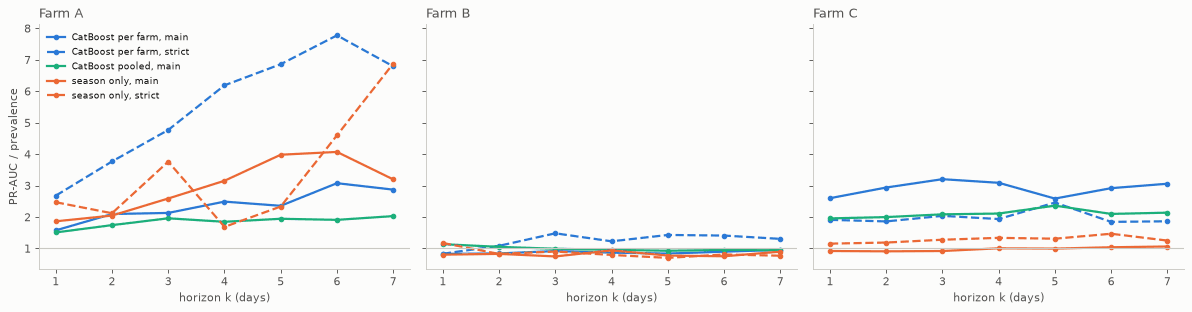

In [14]:
for k in HORIZONS:
    for f in FARMS:
        get_run(f"{f}|full|ys{k}", FEAT[f], SETS[f]["full"], f"ys{k}", "per_farm", seeds=[0])
        get_run(f"{f}|season|ys{k}", FEAT[f], SETS[f]["season"], f"ys{k}", "per_farm", seeds=[0])
        if k < 7:
            get_run(f"{f}|full|y{k}", FEAT[f], SETS[f]["full"], f"y{k}", "per_farm", seeds=[0])
            get_run(f"{f}|season|y{k}", FEAT[f], SETS[f]["season"], f"y{k}", "per_farm", seeds=[0])
    if k < 7:
        get_run(f"pooled|pooled|y{k}", FEAT["pooled"], POOLED_FEATS, f"y{k}", "pooled", seeds=[0])
    get_run(f"pooled|pooled|ys{k}", FEAT["pooled"], POOLED_FEATS, f"ys{k}", "pooled", seeds=[0])


def day_metrics(F, res, target, farm=None, seed=None):
    P = res["pred"]
    P = P[P["seed"] == (seed if seed is not None else P["seed"].min())].sort_values("row")
    y = F[target].to_numpy(float)
    m = np.isfinite(y) & np.isfinite(P["p"].to_numpy())
    if farm is not None:
        m &= F["turbine"].str.startswith(farm).to_numpy()
    yy, pp, ss = y[m], P["p"].to_numpy()[m], P["score"].to_numpy()[m]
    ap = average_precision_score(yy, ss) if 0 < yy.sum() < len(yy) else np.nan
    return {"positives": int(yy.sum()), "prevalence": yy.mean(), "pr_auc": ap,
            "roc_auc": roc_auc_score(yy, ss) if 0 < yy.sum() < len(yy) else np.nan, "lift": ap / yy.mean()}


hz = []
for f in FARMS:
    for k in HORIZONS:
        for tgt, tname in ((f"y{k}", "main"), (f"ys{k}", "strict")):
            for model, run, F_, farm in (("CatBoost per farm", f"{f}|full|{tgt}", FEAT[f], None),
                                         ("CatBoost pooled", f"pooled|pooled|{tgt}", FEAT["pooled"], f),
                                         ("season only", f"{f}|season|{tgt}", FEAT[f], None)):
                hz.append({"farm": f, "target": tname, "k": k, "model": model, **day_metrics(F_, RUNS[run], tgt, farm, seed=0)})
HZ = pd.DataFrame(hz)
HZ.to_csv(OUT / "results_horizons.csv", index=False)
display(HZ.pivot_table(index=["farm", "target", "model"], columns="k", values="roc_auc").round(3))
display(HZ.pivot_table(index=["farm", "target", "model"], columns="k", values="lift").round(2))
display(HZ[HZ["model"] == "CatBoost per farm"].pivot_table(index=["farm", "target"], columns="k", values="positives"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, f in zip(axes, FARMS):
    for (model, tname), color, ls in ((("CatBoost per farm", "main"), BLUE, "-"), (("CatBoost per farm", "strict"), BLUE, "--"),
                                      (("CatBoost pooled", "main"), AQUA, "-"), (("season only", "main"), ORANGE, "-"),
                                      (("season only", "strict"), ORANGE, "--")):
        h = HZ[(HZ["farm"] == f) & (HZ["model"] == model) & (HZ["target"] == tname)]
        ax.plot(h["k"], h["lift"], color=color, ls=ls, lw=2, marker="o", ms=4, label=f"{model}, {tname}")
    ax.axhline(1, color=MUTED, lw=1)
    ax.set_title(f"Farm {f}", loc="left", color=INK2)
    ax.set_xlabel("horizon k (days)")
axes[0].set_ylabel("PR-AUC / prevalence")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "horizon_lift.png", dpi=130, bbox_inches="tight")
show(fig)

**Strict target at the same position.** The strict ROC-AUC above compares the 7 days before an onset with every other
negative day of the year. The fair version: the 7 days before each dataset's own window start, anomaly datasets against
normal datasets (k = 7 strict models, seed 0), as in the feature explorer.

In [15]:
pre = []
for f in FARMS:
    for model, run, F_ in (("CatBoost per farm", f"{f}|full|ys7", FEAT[f]), ("CatBoost pooled", "pooled|pooled|ys7", FEAT["pooled"]),
                           ("season only", f"{f}|season|ys7", FEAT[f])):
        sc = RUNS[run]["pred"].query("seed == 0").sort_values("row")["score"].to_numpy()
        pre.append({"farm": f, "model": model, **matched_pre_onset(F_, sc, ALL_META, f)})
PRE = pd.DataFrame(pre).set_index(["farm", "model"]).round(3)
display(PRE)
PRE.to_csv(OUT / "results_strict_matched.csv")

                        dataset AUC (max score, 7 d before)  permutation p  dataset AUC (mean score, 7 d before) n anomaly / normal
farm model                                                                                                                         
A    CatBoost per farm                                0.736          0.030                                 0.727            11 / 11
     CatBoost pooled                                  0.686          0.071                                 0.719            11 / 11
     season only                                      0.678          0.081                                 0.669            11 / 11
B    CatBoost per farm                                0.796          0.032                                 0.796              6 / 9
     CatBoost pooled                                  0.463          0.627                                 0.370              6 / 9
     season only                                      0.407          0.735  

## 10. Ablations: without ambient temperature, and without any temperature

Same folds and seeds, target k = 7. `no ambient` drops the ambient context feature; `no ambient, no temperature` also drops
every feature built from a temperature column and the temperature group. The residual models of section 3 still use ambient
temperature as a covariate (removing it there would need a rebuild of the deviation table).

In [16]:
abl = []
for f in FARMS:
    for name in ("no_ambient", "no_ambient_no_temp"):
        res = get_run(f"{f}|{name}|y7", FEAT[f], SETS[f][name], "y7", "per_farm")
        r = evaluate(FEAT[f], res, "y7", EVENTS[f], n_boot=200)
        r["matched"] = matched_eval(FEAT[f], r["E"], ALL_META, f)
        EVAL[(f, name)] = r
    for label, name in (("full", "CatBoost per farm"), ("no ambient", "no_ambient"), ("no ambient, no temperature", "no_ambient_no_temp")):
        r = EVAL[(f, name)]
        abl.append({"farm": f, "features": label, "n features": len(SETS[f][{"CatBoost per farm": "full"}.get(name, name)]),
                    "ROC-AUC [95% CI]": ci(r, "roc_auc"), "event recall [95% CI]": ci(r, "recall", "{:.2f}"),
                    "day recall": round(r["point"]["day_recall"], 2), "PR-AUC": round(r["point"]["pr_auc"], 3), "false alarms / turbine-month": round(r["point"]["fa_per_turbine_month"], 2),
                    "matched dataset AUC": round(r["matched"]["dataset AUC (max score)"], 3),
                    "alarm anomaly / normal (matched)": f"{r['matched']['alarm in anomaly datasets']:.2f} / {r['matched']['alarm in normal datasets']:.2f}"})
ABL = pd.DataFrame(abl).set_index(["farm", "features"])
display(ABL)
ABL.to_csv(OUT / "results_ablation.csv")

                                 n features      ROC-AUC [95% CI] event recall [95% CI]  day recall  PR-AUC  false alarms / turbine-month  matched dataset AUC alarm anomaly / normal (matched)
farm features                                                                                                                                                                                  
A    full                               347  0.658 [0.604, 0.756]     0.73 [0.60, 0.90]        0.47   0.127                          0.91                0.645                      0.73 / 0.55
     no ambient                         346  0.681 [0.621, 0.773]     0.73 [0.61, 0.90]        0.49   0.128                          0.94                0.653                      0.73 / 0.55
     no ambient, no temperature         232  0.688 [0.634, 0.786]     0.73 [0.61, 0.90]        0.52   0.115                          0.93                0.636                      0.73 / 0.55
B    full                               

## 11. Which features matter, and which correlate with the label once season is removed

**Model importance.** For the k = 7 models (seed 0), the mean absolute SHAP value on each outer test fold (CatBoost's own
TreeSHAP, up to 3000 labelled test days per fold), averaged over folds weighted by size, and CatBoost's
`PredictionValuesChange`. Both describe what the model used, not whether it generalises.

                                A (% of |SHAP|)  B (% of |SHAP|)  C (% of |SHAP|)  pooled (% of |SHAP|)
kind                                                                                                   
column: pressure                            0.0              0.0             21.9                   0.0
column: electrical                          2.2             12.9             19.8                   0.0
column: temperature                        31.1             41.9             19.4                   0.0
column: power                               9.6              2.9             12.9                   0.0
column: other                               0.7             10.8              8.8                   0.0
column: speed                               5.4              1.6              3.1                   0.0
column: wind                                6.5              4.2              3.0                   0.0
column: pitch                               1.1              1.0

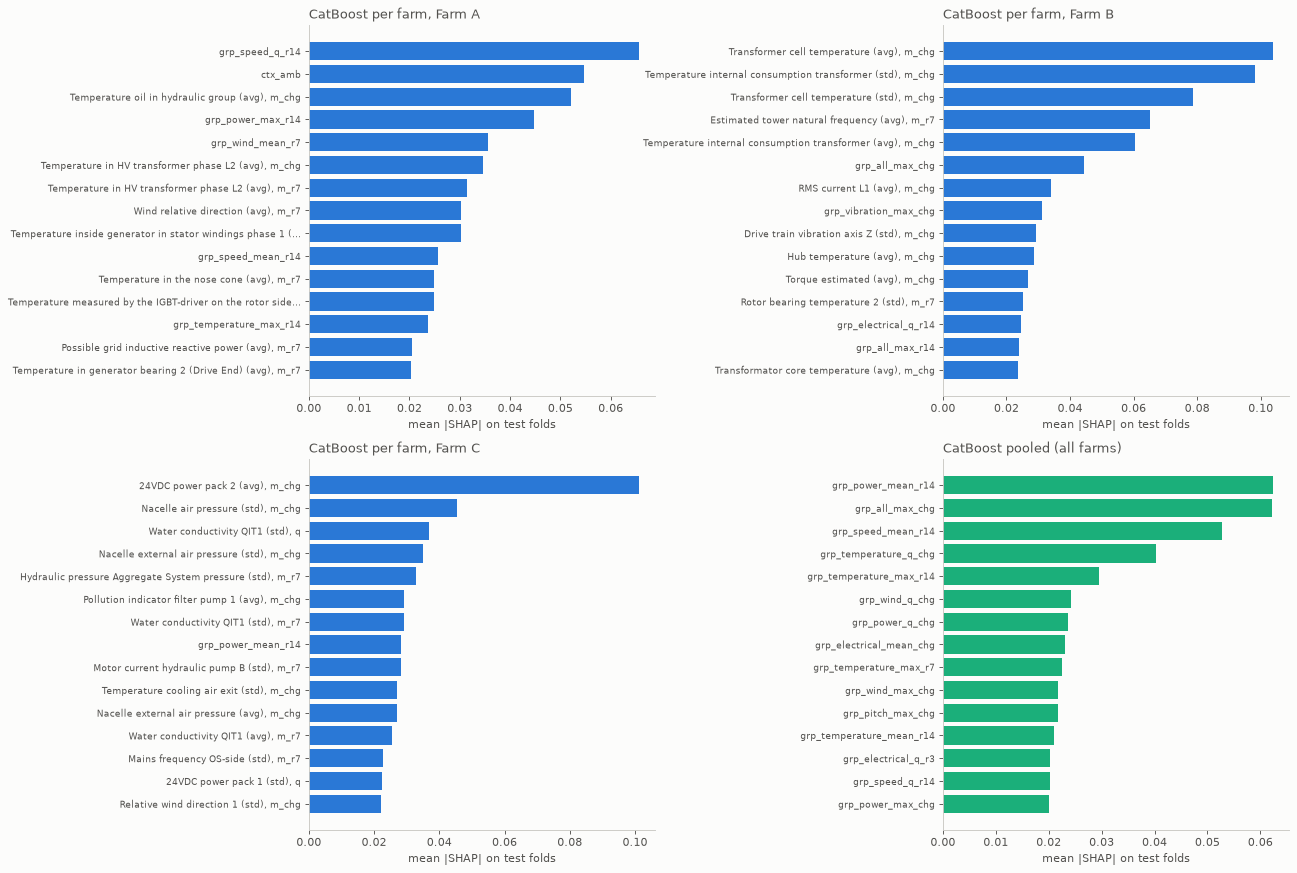

=== A


                      mean |SHAP|  PredictionValuesChange                                                  description                            kind
feature                                                                                                                                               
grp_speed_q_r14            0.0656                  4.4622                                              grp_speed_q_r14                    group: speed
ctx_amb                    0.0547                  2.7889                                                      ctx_amb  context (wind, power, ambient)
sensor_41_avg__m_chg       0.0521                  3.1555              Temperature oil in hydraulic group (avg), m_chg             column: temperature
grp_power_max_r14          0.0447                  2.7810                                            grp_power_max_r14                    group: power
grp_wind_mean_r7           0.0357                  3.0369                                     

=== B


                       mean |SHAP|  PredictionValuesChange                                                description                 kind
feature                                                                                                                                   
sensor_47_avg__m_chg        0.1038                  6.5259                  Transformer cell temperature (avg), m_chg  column: temperature
sensor_31_std__m_chg        0.0981                  5.5502  Temperature internal consumption transformer (std), m_chg  column: temperature
sensor_47_std__m_chg        0.0786                  5.3507                  Transformer cell temperature (std), m_chg  column: temperature
sensor_9_avg__m_r7          0.0650                  3.5070              Estimated tower natural frequency (avg), m_r7        column: other
sensor_31_avg__m_chg        0.0604                  3.6821  Temperature internal consumption transformer (avg), m_chg  column: temperature
grp_all_max_chg            

=== C


                       mean |SHAP|  PredictionValuesChange                                               description                 kind
feature                                                                                                                                  
sensor_213_avg__m_chg       0.1012                  3.6398                           24VDC power pack 2 (avg), m_chg        column: power
sensor_61_std__m_chg        0.0453                  1.9579                         Nacelle air pressure (std), m_chg     column: pressure
sensor_225_std__q           0.0370                  1.7008                          Water conductivity QIT1 (std), q        column: other
sensor_40_std__m_chg        0.0349                  1.6260                Nacelle external air pressure (std), m_chg     column: pressure
sensor_48_std__m_r7         0.0328                  0.9489  Hydraulic pressure Aggregate System pressure (std), m_r7     column: pressure
sensor_95_avg__m_chg        0.0292

=== pooled


                         mean |SHAP|  PredictionValuesChange              description                kind
feature                                                                                                  
grp_power_mean_r14            0.0624                  5.7503       grp_power_mean_r14        group: power
grp_all_max_chg               0.0621                  5.1566          grp_all_max_chg          group: all
grp_speed_mean_r14            0.0528                  4.3056       grp_speed_mean_r14        group: speed
grp_temperature_q_chg         0.0402                  4.4927    grp_temperature_q_chg  group: temperature
grp_temperature_max_r14       0.0296                  2.1906  grp_temperature_max_r14  group: temperature
grp_wind_q_chg                0.0242                  4.1355           grp_wind_q_chg         group: wind
grp_power_q_chg               0.0237                  2.1631          grp_power_q_chg        group: power
grp_electrical_mean_chg       0.0232          

In [17]:
def describe(f, feat):
    if "__" in feat and f in FM:
        col, kind = feat.split("__")
        r = FM[f].set_index("column").loc[col]
        return f"{r['description']} ({r['stat']}), {kind}"
    return feat


def feature_kind(f, feat):
    if feat.startswith("ctx_"):
        return "context (wind, power, ambient)"
    if feat.startswith("grp_"):
        return "group: " + feat.split("_")[1]
    col = feat.split("__")[0]
    return "column: " + FM[f].set_index("column").loc[col, "group"]


IMP = {}
for key, run in [(f, f"{f}|full|y7") for f in FARMS] + [("pooled", "pooled|pooled|y7")]:
    I = RUNS[run]["imp"]
    shap_ = I.groupby("feature").apply(lambda g: np.average(g["mean_abs_shap"], weights=g["n"]))
    T = pd.DataFrame({"mean |SHAP|": shap_, "PredictionValuesChange": I.groupby("feature")["pvc"].mean()})
    T = T.sort_values("mean |SHAP|", ascending=False)
    T["description"] = [describe(key, c) for c in T.index]
    T["kind"] = [feature_kind(key if key in FARMS else "A", c) for c in T.index]
    IMP[key] = T
    T.to_csv(OUT / f"importance_{key}.csv")

share = pd.concat({k: (T.groupby("kind")["mean |SHAP|"].sum() / T["mean |SHAP|"].sum()) for k, T in IMP.items()}, axis=1)
display((100 * share).round(1).fillna(0).sort_values("C", ascending=False).rename(columns=lambda c: f"{c} (% of |SHAP|)"))

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, key in zip(axes.ravel(), FARMS + ["pooled"]):
    T = IMP[key].head(15).iloc[::-1]
    ax.barh(range(len(T)), T["mean |SHAP|"], color=BLUE if key != "pooled" else AQUA)
    ax.set_yticks(range(len(T)))
    ax.set_yticklabels([(d if len(d) < 60 else d[:57] + "...") for d in T["description"]], fontsize=8)
    ax.set_title("CatBoost pooled (all farms)" if key == "pooled" else f"CatBoost per farm, Farm {key}", loc="left", color=INK2)
    ax.set_xlabel("mean |SHAP| on test folds")
fig.tight_layout()
fig.savefig(OUT / "shap_importance.png", dpi=130, bbox_inches="tight")
show(fig)
for key in FARMS + ["pooled"]:
    print(f"=== {key}")
    display(IMP[key].head(10).round(4))

**Season-aware correlation.** For every `full` feature of a farm, on the labelled days (k = 7): the Spearman correlation with
the label, and the **partial** correlation after removing season from both sides (the ranked feature and the label are each
regressed on daily ambient temperature and the sine and cosine of the day of year, and the residuals are correlated).
`season R2` is how much of the ranked feature season explains. The 95% interval of the partial correlation comes from a
cluster bootstrap over turbines (200 resamples, top features only). Day-level correlations are dominated by long windows,
so they describe association, not lead time.

In [18]:
def partial_corr(F, feats, target="y7"):
    d = F[F["usable"] & F[target].notna()]
    S = d[["ctx_amb", "doy_sin", "doy_cos"]].to_numpy(float)
    ok = np.isfinite(S).all(1)
    d, S = d[ok], S[ok]
    y = d[target].to_numpy(float)
    Z = np.column_stack([np.ones(len(S)), S])
    out = []
    for c in feats:
        x = d[c].to_numpy(float)
        m = np.isfinite(x)
        if m.sum() < 200 or np.nanstd(x) == 0:
            continue
        rx, ym, Zm = pd.Series(x[m]).rank().to_numpy(), y[m], Z[m]
        ex = rx - Zm @ np.linalg.lstsq(Zm, rx, rcond=None)[0]
        ey = ym - Zm @ np.linalg.lstsq(Zm, ym, rcond=None)[0]
        out.append({"feature": c, "spearman": np.corrcoef(rx, ym)[0, 1], "partial (season removed)": np.corrcoef(ex, ey)[0, 1],
                    "season R2": 1 - ex.var() / rx.var()})
    return pd.DataFrame(out).set_index("feature"), d


def boot_partial(d, feats, target="y7", n=200, seed=0):
    rng = np.random.default_rng(seed)
    turbs = d["turbine"].unique()
    idx = {t: np.flatnonzero(d["turbine"].to_numpy() == t) for t in turbs}
    res = []
    for _ in range(n):
        rows = np.concatenate([idx[t] for t in rng.choice(turbs, len(turbs))])
        pc, _ = partial_corr(d.iloc[rows], feats, target)
        res.append(pc["partial (season removed)"])
    B = pd.concat(res, axis=1)
    return B.quantile(0.025, axis=1), B.quantile(0.975, axis=1)


CORR = {}
for f in FARMS:
    pc, d = partial_corr(FEAT[f], [c for c in SETS[f]["full"] if c != "ctx_amb"])
    amb = partial_corr(FEAT[f], ["ctx_amb"])[0]
    pc["description"] = [describe(f, c) for c in pc.index]
    pc = pc.reindex(pc["partial (season removed)"].abs().sort_values(ascending=False).index)
    top = pc.index[:10].tolist()
    lo, hi = boot_partial(d, top)
    pc.loc[top, "partial CI low"], pc.loc[top, "partial CI high"] = lo, hi
    CORR[f] = pc
    pc.to_csv(OUT / f"season_aware_correlation_{f}.csv")
    raw_hi = (pc["spearman"].abs() >= 0.1).sum()
    part_hi = (pc["partial (season removed)"].abs() >= 0.1).sum()
    print(f"=== Farm {f}: ambient temperature vs label, Spearman {amb['spearman'].iloc[0]:+.3f}; "
          f"features with |rho| >= 0.10: {raw_hi} before, {part_hi} after removing season (of {len(pc)})")
    display(pc.head(12)[["description", "spearman", "partial (season removed)", "partial CI low", "partial CI high",
                         "season R2"]].round(3))

=== Farm A: ambient temperature vs label, Spearman +0.122; features with |rho| >= 0.10: 13 before, 1 after removing season (of 346)


                                                                     description  spearman  partial (season removed)  partial CI low  partial CI high  season R2
feature                                                                                                                                                         
sensor_31_std__m_chg                            Grid reactive power (std), m_chg    -0.074                    -0.104          -0.186            0.016      0.142
grp_power_max_r14                                              grp_power_max_r14    -0.123                    -0.090          -0.224            0.018      0.055
sensor_34_avg__m_chg                    Averaged voltage in phase 3 (avg), m_chg    -0.025                    -0.089          -0.171           -0.011      0.120
grp_electrical_q_chg                                        grp_electrical_q_chg    -0.047                    -0.087          -0.149           -0.010      0.122
reactive_power_27_std__m_r7  Possi

=== Farm B: ambient temperature vs label, Spearman +0.110; features with |rho| >= 0.10: 69 before, 61 after removing season (of 608)


                                                                       description  spearman  partial (season removed)  partial CI low  partial CI high  season R2
feature                                                                                                                                                           
sensor_47_std__m_chg                     Transformer cell temperature (std), m_chg     0.249                     0.257           0.101            0.350      0.029
sensor_47_avg__m_chg                     Transformer cell temperature (avg), m_chg     0.244                     0.254           0.090            0.349      0.028
sensor_31_avg__m_chg     Temperature internal consumption transformer (avg), m_chg     0.236                     0.205           0.076            0.295      0.194
sensor_31_std__m_chg     Temperature internal consumption transformer (std), m_chg     0.235                     0.203           0.074            0.296      0.198
sensor_52_avg__m_r7   

=== Farm C: ambient temperature vs label, Spearman +0.020; features with |rho| >= 0.10: 86 before, 79 after removing season (of 2050)


                                                         description  spearman  partial (season removed)  partial CI low  partial CI high  season R2
feature                                                                                                                                             
sensor_3_std__m_r7         Active power aeration motor A (std), m_r7     0.089                     0.161          -0.065            0.296      0.047
sensor_142_std__m_r7          Rotational speed aerator A (std), m_r7     0.107                     0.157          -0.013            0.304      0.069
sensor_142_std__q                Rotational speed aerator A (std), q     0.094                     0.154           0.031            0.267      0.060
grp_temperature_max_r14                      grp_temperature_max_r14     0.127                     0.148           0.064            0.217      0.051
sensor_167_std__m_r7     Air temp. transformer container (std), m_r7     0.136                     0.143  

## 12. Calibration: the score as a risk percentage

The CatBoost score is mapped to a probability with an isotonic regression fitted on the training turbines' out-of-fold
scores of each outer fold (grouped CV, never on the test turbine). The reliability plot compares the calibrated risk with
the observed share of positive days, in bins of equal size. Below it: the median risk around the start of every dataset's
own window, anomaly datasets against normal ones, which is what a user would see on the dashboard.

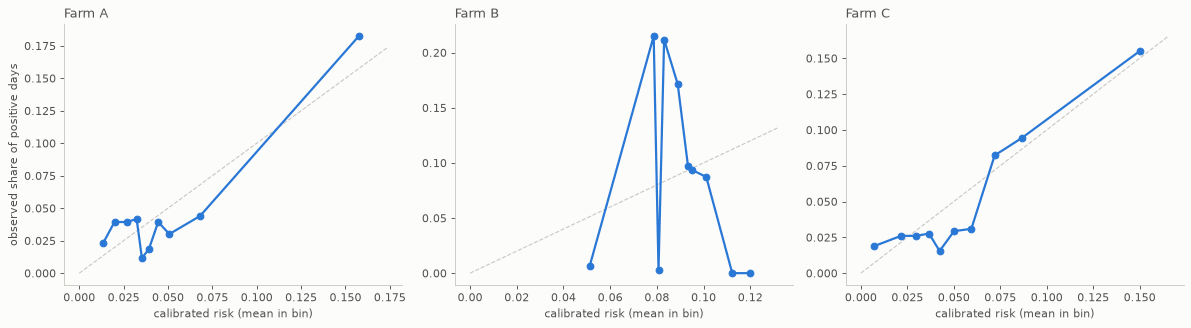

      Brier raw CatBoost  Brier calibrated  Brier prevalence  ECE (10 bins)  max calibrated risk  share of days with risk > 20%
farm                                                                                                                           
A                 0.0429            0.0431            0.0448         0.0170               0.4295                         0.0206
B                 0.0862            0.0816            0.0807         0.0721               0.1218                         0.0000
C                 0.0467            0.0475            0.0481         0.0128               0.9080                         0.0121

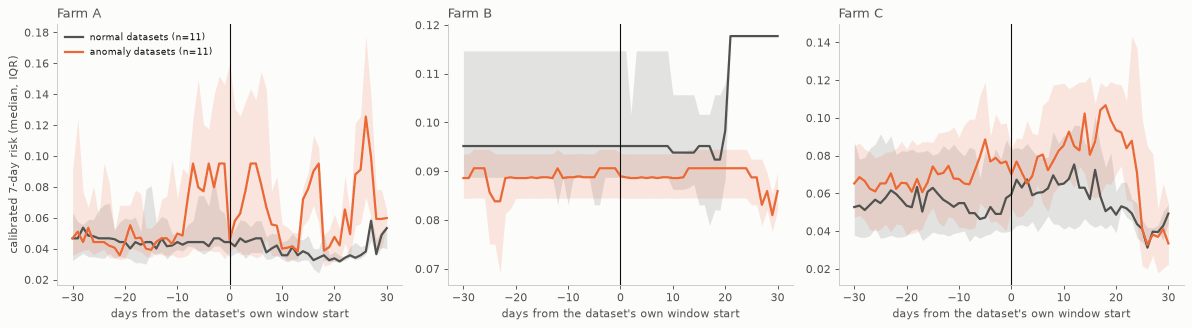

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cal_rows = []
for ax, f in zip(axes, FARMS):
    r = EVAL[(f, "CatBoost per farm")]
    y, p, s = r["y"], r["E"]["p"], r["E"]["score"]
    m = np.isfinite(y) & np.isfinite(p)
    yy, pp, ss = y[m], p[m], s[m]
    q = pd.qcut(pd.Series(pp).rank(method="first"), 10, labels=False)
    g = pd.DataFrame({"p": pp, "y": yy, "q": q}).groupby("q").mean()
    ax.plot([0, g["p"].max() * 1.1], [0, g["p"].max() * 1.1], color=MUTED, lw=1, ls="--")
    ax.plot(g["p"], g["y"], color=BLUE, marker="o", lw=2)
    ax.set_title(f"Farm {f}", loc="left", color=INK2)
    ax.set_xlabel("calibrated risk (mean in bin)")
    ece = float(np.average(np.abs(g["p"] - g["y"]), weights=pd.Series(q).value_counts().sort_index()))
    cal_rows.append({"farm": f, "Brier raw CatBoost": brier_score_loss(yy, np.clip(ss, 0, 1)),
                     "Brier calibrated": brier_score_loss(yy, pp), "Brier prevalence": brier_score_loss(yy, np.full(len(yy), yy.mean())),
                     "ECE (10 bins)": ece, "max calibrated risk": pp.max(), "share of days with risk > 20%": (pp > 0.2).mean()})
axes[0].set_ylabel("observed share of positive days")
fig.tight_layout()
fig.savefig(OUT / "calibration.png", dpi=130, bbox_inches="tight")
show(fig)
display(pd.DataFrame(cal_rows).set_index("farm").round(4))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=False)
for ax, f in zip(axes, FARMS):
    E = EVAL[(f, "CatBoost per farm")]["E"]
    F = FEAT[f]
    curves = {"anomaly": [], "normal": []}
    for _, rr in ALL_META[ALL_META["farm"] == f].iterrows():
        s0 = to_day([rr["event_start"]])[0]
        m = (F["segment"] == rr["segment"]).to_numpy()
        rel = F["day"].to_numpy()[m] - s0
        curves[rr["label"]].append(pd.Series(E["p"][m], index=rel).reindex(range(-30, 31)))
    for lab, color in (("normal", INK2), ("anomaly", ORANGE)):
        C = pd.concat(curves[lab], axis=1)
        ax.fill_between(C.index, C.quantile(0.25, axis=1), C.quantile(0.75, axis=1), color=color, alpha=0.15, lw=0)
        ax.plot(C.index, C.median(axis=1), color=color, lw=2, label=f"{lab} datasets (n={C.shape[1]})")
    ax.axvline(0, color=INK, lw=1)
    ax.set_title(f"Farm {f}", loc="left", color=INK2)
    ax.set_xlabel("days from the dataset's own window start")
axes[0].set_ylabel("calibrated 7-day risk (median, IQR)")
axes[0].legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(OUT / "risk_around_window.png", dpi=130, bbox_inches="tight")
show(fig)

## 13. Deliverable: daily risk per turbine for a test week

Every day of every turbine already has an out-of-fold prediction, so any week is a test week. For each farm the week shown is
the one around an anomaly onset (4 days before to 2 days after) that covers the most turbines of the farm. Columns:

- `risk_k1` ... `risk_k7`: calibrated probability (in %) that the turbine is inside, or enters, an anomaly window within k
  days (CatBoost per farm; k = 7 is the three-seed ensemble, the others seed 0), made monotone in k;
- `above_threshold`: the k = 7 score reaches the fold's threshold (majority of seeds); `alarm`: the 2-of-3-days persistence
  rule is met. Only `alarm` should notify anyone;
- `deviation_pct`: where today's overall deviation index sits among the turbine's own negative days of the past year
  (t-365 to t-30), in percent. **Descriptive only**, not a health percentage;
- `truth_k7`, `in_window`: the label, for checking.

Saved to `dataset/wind_turbine_scada_fault/cache/catboost_test_week.parquet`; the same columns for every day are in
`cache/catboost_baseline/oof_daily_risk.parquet` (for the comparison with the LSTM).

In [20]:
def deviation_percentile(F):
    out = np.full(len(F), np.nan)
    di = F["grp_all_mean_d"].to_numpy(float)
    neg = (F["y7"] == 0).to_numpy() & F["usable"].to_numpy()
    for _, idx in F.groupby("segment", sort=False).indices.items():
        day = F["day"].to_numpy()[idx]
        for j, i in enumerate(idx):
            if not np.isfinite(di[i]):
                continue
            ref = idx[(day >= day[j] - 365) & (day <= day[j] - 30) & neg[idx] & np.isfinite(di[idx])]
            if len(ref) >= 30:
                out[i] = 100.0 * (di[ref] < di[i]).mean()
    return out


RISK = []
for f in FARMS:
    F = FEAT[f]
    E = EVAL[(f, "CatBoost per farm")]["E"]
    R = F[["farm", "turbine", "segment", "day", "usable", "in_window", "days_to_onset", "y7"]].copy()
    risks = np.column_stack([RUNS[f"{f}|full|y{k}"]["pred"].query("seed == 0").sort_values("row")["p"].to_numpy()
                             if k < 7 else E["p"] for k in HORIZONS])
    risks = np.fmax.accumulate(risks, axis=1)
    for j, k in enumerate(HORIZONS):
        R[f"risk_k{k}"] = np.round(100 * risks[:, j], 1)
    R["score_k7"] = E["score"]
    R["above_threshold"], R["alarm"] = E["above"], E["alarm"]
    R["deviation_pct"] = np.round(deviation_percentile(F), 1)
    R["date"] = pd.to_datetime(R["day"], unit="D")
    R = R.rename(columns={"y7": "truth_k7"})
    R.loc[~R["usable"], [f"risk_k{k}" for k in HORIZONS] + ["score_k7"]] = np.nan
    RISK.append(R)
RISK = pd.concat(RISK, ignore_index=True)
RISK.to_parquet(OUT / "oof_daily_risk.parquet")

weeks = []
for f in FARMS:
    R = RISK[(RISK["farm"] == f) & RISK["usable"]]
    best = None
    for _, e in EVENTS[f].sort_values("s").iterrows():
        days = range(e["s"] - 4, e["s"] + 3)
        n = R[R["day"].isin(days)].groupby("turbine")["day"].nunique()
        cover = int((n >= 5).sum())
        if best is None or cover > best[0]:
            best = (cover, e, days)
    cover, e, days = best
    W = RISK[(RISK["farm"] == f) & RISK["day"].isin(days)].copy()
    W["week_of_event"] = e["event_ids"]
    weeks.append(W)
    print(f"Farm {f}: week around the onset of event {e['event_ids']} (turbine {e['turbine']}), {cover} turbines with data")
WEEK = pd.concat(weeks, ignore_index=True)
cols = ["farm", "turbine", "segment", "date", "risk_k1", "risk_k3", "risk_k7", "above_threshold", "alarm", "deviation_pct",
        "truth_k7", "in_window", "week_of_event"]
WEEK = WEEK[cols + [c for c in WEEK.columns if c not in cols]]
WEEK.to_parquet(CACHE / "catboost_test_week.parquet")
for f in FARMS:
    W = WEEK[WEEK["farm"] == f].copy()
    W["cell"] = W["risk_k7"].map(lambda v: "" if pd.isna(v) else f"{v:.0f}%") + np.where(W["alarm"], " ALARM", "") \
        + np.where(W["truth_k7"] == 1, " *", "")
    print(f"=== Farm {f}: 7-day risk per turbine and day (ALARM = persistent alarm, * = truly positive)")
    display(W.pivot_table(index=["turbine", "segment"], columns=W["date"].dt.strftime("%m-%d"), values="cell", aggfunc="first").fillna("-"))

Farm A: week around the onset of event 40 (turbine A10), 4 turbines with data
Farm B: week around the onset of event 7 (turbine B13), 3 turbines with data
Farm C: week around the onset of event 81 (turbine C38), 7 turbines with data
=== Farm A: 7-day risk per turbine and day (ALARM = persistent alarm, * = truly positive)


date            12-20 12-21 12-22 12-23 12-24 12-25 12-26
turbine segment                                          
A00     A00-3      6%    6%    4%    4%    4%    4%    5%
A10     A10-3    2% *  2% *  2% *  2% *  2% *  2% *  2% *
A11     A11-2      5%    5%    5%    5%    5%    5%    5%
A21     A21-2      3%    4%    4%    3%    3%    3%    3%

=== Farm B: 7-day risk per turbine and day (ALARM = persistent alarm, * = truly positive)


date            06-26 06-27 06-28 06-29 06-30 07-01 07-02
turbine segment                                          
B02     B02-0     12%   12%   12%   12%   12%   12%   11%
B06     B06-1      9%    9%    9%    9%    9%    9%    9%
B13     B13-0    9% *  9% *  9% *  9% *  9% *  9% *  9% *

=== Farm C: 7-day risk per turbine and day (ALARM = persistent alarm, * = truly positive)


date                 11-13      11-14      11-15      11-16      11-17      11-18      11-19
turbine segment                                                                             
C16     C16-0    14% ALARM  13% ALARM  11% ALARM  11% ALARM  14% ALARM  14% ALARM  11% ALARM
C32     C32-0    22% ALARM  17% ALARM  17% ALARM  19% ALARM  19% ALARM  45% ALARM  45% ALARM
C33     C33-0           4%         4%         4%         3%         4%         5%         5%
C34     C34-0           4%         5%         4%         4%         5%         9%         8%
C35     C35-1           7%         5%         5%         4%         5%        10%         7%
C38     C38-0         6% *       6% *       6% *       4% *       4% *       9% *       9% *
C53     C53-0    10% ALARM   8% ALARM         8%         7%         7%        11%         9%

**Every event, one line.** Whether the persistent alarm fired between 7 days before onset and the end of the window, the first
alarm day relative to the onset (negative = after), and the highest calibrated 7-day risk in that span.

In [21]:
ev_rows = []
for f in FARMS:
    R = RISK[RISK["farm"] == f]
    for _, e in EVENTS[f].iterrows():
        w = R[(R["segment"] == e["segment"]) & (R["day"] >= e["s"] - 7) & (R["day"] <= e["e"])]
        al = w[w["alarm"]]
        ev_rows.append({"farm": f, "event": e["event_ids"], "turbine": e["turbine"], "length (days)": e["length_days"],
                        "description": META[f].set_index("event_id").loc[int(e["event_ids"].split(",")[0]), "description"],
                        "detected": len(al) > 0, "first alarm vs onset (days)": (al["day"].min() - e["s"]) if len(al) else np.nan,
                        "max 7-day risk %": w["risk_k7"].max()})
EVT = pd.DataFrame(ev_rows)
display(EVT.set_index(["farm", "event"]))
EVT.to_csv(OUT / "events_detection.csv", index=False)

           turbine  length (days)                                                  description  detected  first alarm vs onset (days)  max 7-day risk %
farm event                                                                                                                                             
A    26        A00              8                                              Hydraulic group      True                         -7.0              13.5
     0         A00             15                                    Generator bearing failure      True                         -3.0              17.6
     73        A00              8                                              Hydraulic group     False                          NaN               5.5
     10        A10              8                                              Gearbox failure      True                         -7.0              27.3
     40        A10             32                                    Generator bearing f

## 14. Conclusions, and what does not work

All numbers are out-of-fold, target k = 7 ("inside or entering an anomaly window within 7 days"), from the tables above.

**Headline (ROC-AUC and recall).**

| farm | model | ROC-AUC pooled | ROC-AUC within turbine | event recall | false alarms / turbine-month |
|---|---|---|---|---|---|
| A | CatBoost per farm | 0.658 [0.604, 0.756] | 0.695 | 0.73 (8 of 11) | 0.91 |
| A | season only | 0.645 | 0.673 | 0.91 | 3.21 (budget broken) |
| B | CatBoost per farm | 0.403 [0.307, 0.500] | 0.550 | 0.33 (2 of 6) | 1.23 |
| B | deviation rule | 0.527 | 0.608 | 0.83 | 1.01 |
| C | CatBoost per farm | 0.714 [0.584, 0.813] | 0.728 | 0.85 (23 of 27) | 1.06 |
| C | season only | 0.447 | 0.496 | 0.96 | 3.20 (budget broken) |

**What the baseline does.**

1. **Farm C is the only farm where CatBoost clearly beats the season-only model**: ROC-AUC +0.27 [+0.13, +0.38], PR-AUC
   0.119 against 0.046, and at the same position anomaly datasets get an alarm in 85% of cases against 55% of normal
   datasets (dataset AUC 0.69, permutation p 0.008; the plain deviation rule does as well there, 0.68, p 0.010).
2. **Farm A: not shown to beat season.** ROC-AUC difference +0.01 [-0.14, +0.17]; at the same position the season-only
   model separates anomaly from normal datasets as well (0.69) as CatBoost (0.65, permutation p 0.13). Removing ambient temperature and every
   temperature feature does not lower CatBoost (ROC-AUC 0.66 to 0.69), so the per-farm model is not just reading the
   calendar, but it is also no better than the calendar. Of the 13 Farm A features with |Spearman| >= 0.10, one survives
   once season is removed.
3. **Farm B: nothing works.** Six events. CatBoost per farm is below 0.5 pooled ROC-AUC and at the same position ranks
   normal datasets above anomaly ones (dataset AUC 0.24). The plain deviation rule is the best model in B.
4. **The pooled model (one model, three farms, group features only) is worse than the per-farm models** in A and C (ROC-AUC
   0.61 and 0.66 against 0.66 and 0.71) and as poor in B. 44 events in one model did not make up for losing the per-column
   features.

**What does not work, said plainly.**

- **No convincing early warning.** The strict target (only the 7 days before onset), compared at the same position,
  anomaly against normal datasets, with the strict CatBoost per farm: dataset AUC 0.74 in A (permutation p 0.03), 0.80 in B
  (p 0.03), 0.62 in C (p 0.06). These are 9 tests (3 models, 3 farms) without correction, so none survives a Bonferroni
  correction; in A the season-only model reaches 0.68 on the same test, and B's 0.80 contradicts every other B result. It is
  a hint worth re-testing with the LSTM, not evidence of a precursor. The alarms that fire "before onset" are mostly the base
  alarm rate: normal datasets get an alarm in the same 3-week span 55% of the time.
- **Event recall is flattering on its own.** Windows last 2 to 67 days and the budget allows about one alarm a month, so a
  long window catches an alarm by chance. Read recall only next to the same-position alarm rate of normal datasets.
- **The risk percentage is weak.** The calibrated Brier score is barely below a constant (A 0.0431 against 0.0448, C 0.0475
  against 0.0481) and above it in B. Few days get a risk over 20% (2% of days in A, none in B, 1% in C).
- **The threshold transfers badly for slow scores.** The season-only model met the budget on training turbines and produced
  2.3 to 3.2 false alarms per turbine-month on test turbines. CatBoost and the deviation rule stayed near 1.
- **The test week shows misses.** The weeks were chosen by coverage, not by outcome; in A and B the turbine with the onset
  has the lowest (B: tied lowest) risk of its farm that week, and in C three turbines alarm while the one with the converter failure does not.
- **Health percentage: none.** There is no ground truth for degradation and no precursor to interpolate. The deliverable
  gives a calibrated risk and a deviation percentile against the turbine's own past negative days, the latter descriptive only.

**Where the specification did not hold on the data.**

- De-duplicating (turbine, day) across overlapping datasets: 12 of the 22 overlapping same-turbine pairs carry different data
  on the same anonymised timestamps. Only identical overlaps are merged; the unit is (timeline, day). Onsets truly inside
  another dataset's train part: 2 (A), 1 (B), 2 (C) anomaly onsets, not 8, 1 and 11.
- The baseline t-365 to t-60 grows with the position in the dataset and leaks that position (section 3). A fixed 120-day
  window [t-180, t-60) is used instead.
- Farm A `sensor_44` to `sensor_51` are energies per 10-minute interval, not cumulative counters. They stay excluded (they
  split energy by generator state: disconnected, star, delta, which is close to an operating-state flag).
- Day of year is a valid season feature: in every dataset ambient temperature peaks around day 210 to 220, so the timestamp
  shifts preserve the season.

**For the LSTM.** Same folds (`cv_folds.parquet`), same labels (rebuild them with section 4, or join on `segment` and `day`
from `oof_daily_risk.parquet`), and the same three checks: beat the season-only model with a paired interval, beat it at the
same position (anomaly against normal datasets), and keep the false-alarm budget on the test turbines. A sequence model needs
to clear Farm C's 0.71 ROC-AUC and 0.69 same-position AUC to count as better.